<figure style="text-align: center;">
  <img src="_static/intro/title_page.png" style="display: block; margin: 0 auto; width: 100%;">
</figure>

### Linear Algebra Basics

Michael J. Pyrcz, Professor, The University of Texas at Austin 

[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

Chapter of e-book "Applied Machine Learning in Python: a Hands-on Guide with Code". 

```{admonition} Cite this e-Book as:
:class: remove-from-content-only

Pyrcz, M.J., 2024, *Applied Machine Learning in Python: A Hands-on Guide with Code* [e-book]. Zenodo. doi:10.5281/zenodo.15169139 [![DOI](https://zenodo.org/badge/863274676.svg)](https://doi.org/10.5281/zenodo.15169139) 
```

The workflows in this book and more are available here:

```{admonition} Cite the MachineLearningDemos GitHub Repository as:
:class: remove-from-content-only

Pyrcz, M.J., 2024, *MachineLearningDemos: Python Machine Learning Demonstration Workflows Repository* (0.0.3) [Software]. Zenodo. DOI: 10.5281/zenodo.13835312. GitHub repository: https://github.com/GeostatsGuy/MachineLearningDemos [![DOI](https://zenodo.org/badge/862519860.svg)](https://zenodo.org/doi/10.5281/zenodo.13835312)
```

By Michael J. Pyrcz <br />
&copy; Copyright 2024.

This chapter is a summary of **Linear Algebra** prerequisites for machine learning. 

**YouTube Lecture**: check out my lecture on TBA. For your convenience here's a summary of salient points.

Here's a short summary of linear algebra prerequisites, specifically operations and concepts essential for machine learning. This chapter is part of the resources that I include for my courses in Machine Learning at the Cockrell School of Engineering and Jackson School of Geosciences at the University of Texas at Austin.  


#### Inventory of Covered Linear Algebra Concepts and Operations

We will cover the following linear algebra concepts with descriptions, equations, and demonstrations with visualizations:

* these linear algebra concepts are critical for model assessment and training, neural networks, regression, PCA, transformers, etc.

#### Vector Fundamentals List

1. **Vector** - ordered collection of numerical values

2.	**Vector Magnitude** - length of a vector

3.	**Unit Vector** - vector with magnitude equal to one

4.	**Vector Addition** - element-by-element addition

5.	**Vector Subtraction** - element-by-element subtraction

6.	**Scalar Vector Multiplication** - multiplication of a vector by a scalar

7.	**Linear Combination** - weighted sum of vectors

8.	**Vector Norms** - L1, L2, and maximum norms

9.	**Dot Product** - sum of element-wise products

10.	**Cosine Similarity	Similarity** - alignment based on the angle between vectors


#### Matrix Fundamentals List

1. **Matrix** - two-dimensional numerical array

2. **Matrix Dimensions** - rows, columns, and matrix shape

3. **Matrix Transpose** - interchanging rows and columns

4. **Matrix Addition** - element-by-element matrix addition

5. **Scalar Multiplication** - multiplying every matrix element by a scalar

6. **Element-wise Multiplication** - Hadamard product

7. **Matrix-Vector Multiplication** - transforming a vector using a matrix

8. **Matrix Multiplication** - combining two matrices

9. **Identity Matrix** - matrix equivalent of multiplication by one

10. **Inverse Matrix** - matrix inverse and its applications


#### Vector Geometry and Projections List

1. **Angle Between Vectors** - geometric relationship between vectors

2. **Orthogonality** - perpendicular vectors and zero dot product

3. **Vector Projection** - projecting one vector onto another

4. **Orthogonal Projection** - projection onto a perpendicular basis or subspace

5. **Non-Orthogonal Projection** - projection using a non-orthogonal basis

6. **Residual Vector** - difference between a vector and its projection

7. **Distance Between Vectors** - Euclidean distance


#### Matrix Properties and Linear Transformations List

1. **Linear Transformation** - matrix as a transformation of space

2. **Matrix Rank** - number of independent rows or columns

3. **Determinant** - scaling factor and invertibility

4. **Trace** - sum of diagonal elements

5. **Eigenvalues and Eigenvectors** - special directions preserved by a transformation

6. **Singular Value Decomposition** - decomposition into three matrices

7. **Least Squares Solution** - solving an overdetermined linear system

Before we walk through these, we need to load some packages, define some convenience functions for plotting, and make some simple synthetic vectors and matrices.


#### Load the Required Libraries

The following code loads the required libraries. These should have been installed with Anaconda 3.

In [2]:
suppress_warnings = True                                      # toggle to supress warnings
import numpy as np                                            # ndarrys for gridded data
import os                                                     # set working directory, run executables
import matplotlib.pyplot as plt                               # plotting
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, AutoLocator) # control of axes ticks
plt.rc('axes', axisbelow=True)                                # grid behind plotting elements
if suppress_warnings == True:  
    import warnings                                           # supress any warnings for this demonstration
    warnings.filterwarnings('ignore') 
seed = 13                                                     # random number seed for workflow repeatability

#### Set the Working Directory

I always like to do this so I don't lose files and to simplify subsequent read and writes (avoid including the full address each time). Set this to your working directory, with the above mentioned [data](MachineLearning_glossary_d_f.ipynb#data) file.

In [3]:
#os.chdir("c:/PGE383")                                        # set the working directory

#### Define Functions

We define a convenience function to format our plots,

* **format_3d_plot** -  add axis labels, gridlines and origin lines, and legend

* **plot_matrix** - plot matrix, add labels and titles, add value labels in cells, and outline cells

In [4]:
def format_3d_plot(ax,label_offset,title,fix_third):
    ax.set_xlabel('Component 1'); ax.set_ylabel('Component 2'); 
    if fix_third == True:
        fig.text(label_offset, 0.50, 'Component 3',rotation=90, va='center', ha='center')
    else:
        ax.set_zlabel('Component 3')

    ax.set_xlim(-0.1, 1.0); ax.set_ylim(-0.3, 1.0); ax.set_zlim(-0.1, 1.5)
    
    ax.plot([0, 0], ax.get_ylim(), [0, 0], color='black', linewidth=1.5) # dark zero-coordinate axes
    ax.plot(ax.get_xlim(), [0, 0], [0, 0], color='black', linewidth=1.5)
    ax.plot([0, 0], [0, 0], ax.get_zlim(), color='black', linewidth=1.5)
    ax.set_title(title)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.legend(loc='upper left', bbox_to_anchor=(0.0, 1.0)) 

def plot_matrix(ax,matrix,name,cmap='Blues',vmin=0.0,vmax=1.0,colorbar=False):
    im = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(name); ax.set_xlabel('Column'); ax.set_ylabel('Row')
    ax.set_xticks(np.arange(3)); ax.set_yticks(np.arange(3))

    for i in range(matrix.shape[0]):                                     # annotate matrix elements
        for j in range(matrix.shape[1]):
            ax.text(j, i, f'{matrix[i, j]:.2f}',ha='center', va='center', color='black')

    ax.set_xticks(np.arange(-0.5, 3, 1), minor=True); ax.set_yticks(np.arange(-0.5, 3, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=2); ax.tick_params(which='minor', bottom=False, left=False)

    if colorbar == True:
        fig.colorbar(im, ax=ax, label='Matrix Value', shrink=0.8)

#### Simple Vectors and Matrices

Let's make some simple vectors and matrices to demonstrate linear algebra vector and matrix operations and concepts.

* $\bf{x}$ - vector with length 3.

* $\bf{y}$ - vector with length 3.
 
* $\bf{z}$ - vector with length 3, orthogonal to vector $\bf{x}$.

* $\bf{A}$ - symmetric 3 x 3 matrix, with relatively large diagonal values and smaller off-diagonal values. Useful for demonstrating matrix structure and multiplication.

* $\bf{B}$ - asymmetric 3 x 3 matrix, with different off-diagonal relationships. Useful for demonstrating matrix multiplication and the difference between AB and BA.

* $\bf{I}$ - identity 3 x  3 matrix, with ones along the diagonal and zeros elsewhere. Multiplication by I leaves a matrix unchanged.

In [8]:
x = np.array([0.20, 0.40, 0.60])                              # define three vectors
y = np.array([0.30, 0.50, 0.70])
z = np.array([0.40, -0.20, 0.00])

A = np.array([[0.80, 0.10, 0.05],                             # define a 3 x 3 matrix A
              [0.10, 0.70, 0.20],
              [0.05, 0.20, 0.60]])

B = np.array([[0.60, 0.30, 0.10],                             # define a 3 x 3 matrix B
              [0.10, 0.50, 0.40],
              [0.20, 0.10, 0.70]])

I = np.eye(3)                                                 # define a 3 x 3 identity matrix I

index = np.arange(1,4,1)

Now let's go through all the linear algebra vector and matrix opperations in order.

* we start by defining a vector

#### Vector 

A vector is an ordered collection of numerical values. We can represent our 3 simple vectors as:

$\bf{x} = \begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix}$
$\qquad$
$\bf{y} = \begin{bmatrix} 0.30 \\ 0.50 \\ 0.70 \end{bmatrix}$
$\qquad$
$\bf{z} = \begin{bmatrix} 0.40 \\ -0.20 \\ 0.00 \end{bmatrix}$

and we also can plot our vectors together.

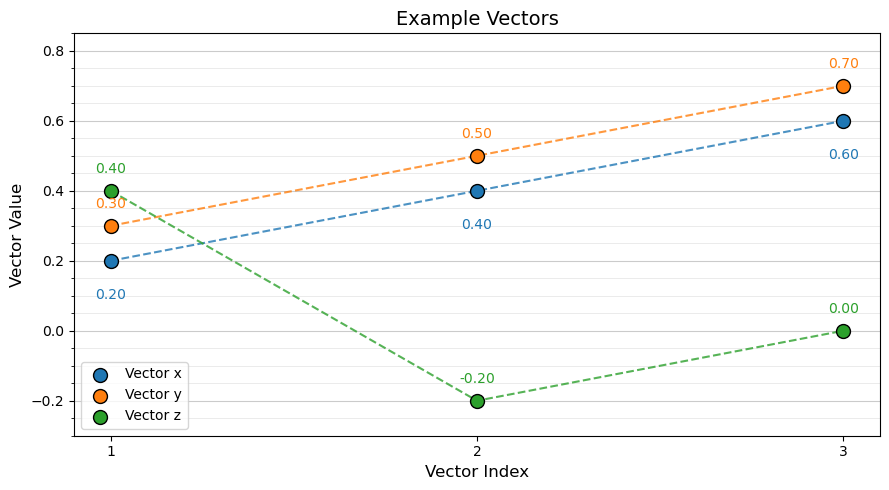

In [11]:
plt.figure(figsize=(9, 5))                                    # plot 3 vectors as line plots
plt.plot(index, x, '--', color='tab:blue', alpha=0.8, linewidth=1.5, zorder=1) # vector x
plt.scatter(index, x, color='tab:blue', edgecolor='black',s=100, label='Vector x', zorder=2)

plt.plot(index, y, '--', color='tab:orange', alpha=0.8,linewidth=1.5, zorder=1) # vector y
plt.scatter(index, y, color='tab:orange', edgecolor='black',s=100, label='Vector y', zorder=2)

plt.plot(index, z, '--', color='tab:green', alpha=0.8,linewidth=1.5, zorder=1) # vector z
plt.scatter(index, z, color='tab:green', edgecolor='black',s=100, label='Vector z', zorder=2)

for i in range(3):                                            # value labels
    plt.text(index[i], x[i] - 0.11, f'{x[i]:.2f}',ha='center', fontsize=10, color='tab:blue')
    plt.text(index[i], y[i] + 0.05, f'{y[i]:.2f}',ha='center', fontsize=10, color='tab:orange')
    plt.text(index[i], z[i] + 0.05, f'{z[i]:.2f}',ha='center', fontsize=10, color='tab:green')

plt.xlabel('Vector Index', fontsize=12); plt.ylabel('Vector Value', fontsize=12); plt.title('Example Vectors', fontsize=14)

plt.gca().set_yticks(np.arange(-0.3, 0.9, 0.05), minor=True)  # two-level horizontal gridlines
plt.gca().set_xticks(index, minor=False)
plt.grid(True, axis='y', which='major', linestyle='-', linewidth=0.8, alpha=0.65)
plt.grid(True, axis='y', which='minor', linestyle='-', linewidth=0.5, alpha=0.35)

plt.legend(loc='lower left');
plt.tight_layout(); plt.show()


#### Vector Magnitude

The magnitude (length) of a vector is the straight-line distance from its tail (starting point) to its head (endpoint).

* if we assume the vector tail is at location $\left[ 0, 0, \ldots, 0 \right]$, then we  can calculate vector magnitude as,

$$
\|\bf{x}\| = \sqrt{\sum_{i=1}^{n} (x_i - 0)^2} = \sqrt{\sum_{i=1}^{n} x_i^2} = \sqrt{x_1^2+x_2^2+\cdots+x_n^2}
$$

For our three simple vectors we calculate vector magnitude as,

$$
\|\bf{x}\| = \sqrt{0.20^2+0.40^2+0.60^2} = 0.748 \qquad
\|\bf{y}\| = \sqrt{0.30^2+0.50^2+0.70^2} = 0.911 \qquad
\|\bf{z}\| = \sqrt{0.40^2+(-0.20)^2+0.00^2} = 0.447
$$

Uses of vector magnitude in machine learning include:

- **L2 norms** calculated over the error vector to summarize prediction error with a single value
  
- **Regularization terms**, including the squared L2 norm of model weights used in ridge regression
  
- **Gradient magnitude** to monitor parameter updates and identify exploding gradients

- **Euclidean distance** between feature vectors for nearest neighbor searches and clustering

- **Residual** or **reconstruction-error magnitude** for anomaly detection

- **Unit-vector normalization** to control vector scale while preserving direction



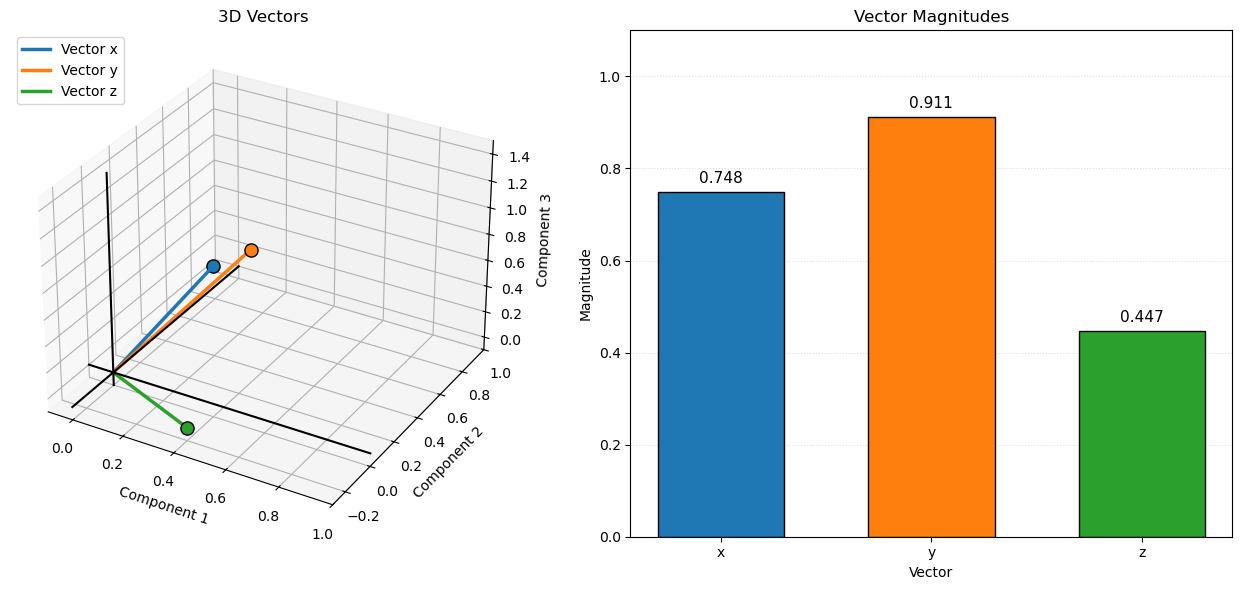

In [251]:
mag_x = np.linalg.norm(x)                                     # calculate vector magnitudes
mag_y = np.linalg.norm(y)
mag_z = np.linalg.norm(z)

plt.figure(figsize=(13, 6))

ax1 = plt.subplot(121, projection='3d')                       # left: 3D vector visualization
vectors = [x, y, z]
colors = ['tab:blue', 'tab:orange', 'tab:green']
labels = ['Vector x', 'Vector y', 'Vector z']

for vec, color, label in zip(vectors, colors, labels):
    ax1.plot([0, vec[0]], [0, vec[1]], [0, vec[2]],color=color, linewidth=2.5, label=label)
    ax1.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=90, zorder=3)

format_3d_plot(ax1,0.88,"3D Vectors",False)                   # add axis labels, origin lines and legend

ax2 = plt.subplot(122)                                        # right: vector magnitudes
magnitudes = [mag_x, mag_y, mag_z]
bars = ax2.bar(['x', 'y', 'z'], magnitudes, color=colors,edgecolor='black', width=0.6)

for bar, mag in zip(bars, magnitudes):
    ax2.text(bar.get_x() + bar.get_width()/2, mag + 0.02,f'{mag:.3f}', ha='center', fontsize=11)

ax2.set_xlabel('Vector'); ax2.set_ylabel('Magnitude'); ax2.set_title('Vector Magnitudes')
ax2.set_ylim(0, 1.1); ax2.grid(True, axis='y', linestyle=':', alpha=0.4)

plt.tight_layout(); plt.show()

#### Unit Vector 

Normalized the vector such that the vector magnitude (vector length) is equal to one.

$$
\|\hat{\bf{x}}\| = 1.0
$$

This is accomplished by dividing each component of the original vector, $\bf{x}$, by its magnitude to produce a unit vector, \\(\hat{\mathbf{x}}\\), with length 1.

$$
\hat{\bf{x}} = \frac{\bf{x}}{\|\bf{x}\|}
$$

Uses of unit vectors in machine learning include:

- **Cosine similarity** – normalize feature or embedding vectors to unit magnitude so similarity comparisons focus on direction rather than magnitude.

- **Text embeddings** – normalize document and word embeddings for semantic similarity searches.

- **Gradient normalization** – normalize gradient vectors to control update direction independently of gradient magnitude.

- **Directional features** – represent directions independently of scale in geometric and spatial machine learning applications.

- **Numerical stability** – normalize input vectors to control differences in feature magnitude and improve optimization behavior.

- **Projection** – use a unit vector to define a direction when calculating scalar projections and vector components.

Let's calculate and visualize unit vectors.

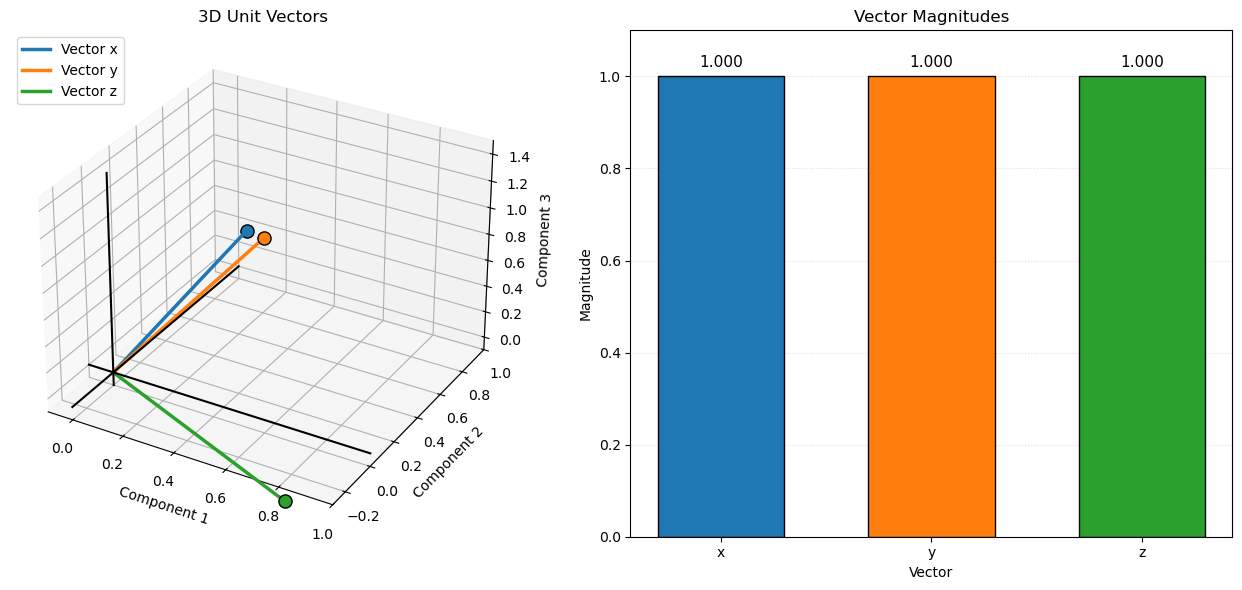

In [12]:
x_hat = x / np.linalg.norm(x)                                 # normalize vectors to unit length
y_hat = y / np.linalg.norm(y)
z_hat = z / np.linalg.norm(z)

mag_x_hat = np.linalg.norm(x_hat)                             # calculate vector magnitudes
mag_y_hat = np.linalg.norm(y_hat)
mag_z_hat = np.linalg.norm(z_hat)

plt.figure(figsize=(13, 6))

ax1 = plt.subplot(121, projection='3d')                       # left: 3D vector visualization

vectors = [x_hat, y_hat, z_hat]; colors = ['tab:blue', 'tab:orange', 'tab:green']; labels = ['Vector x', 'Vector y', 'Vector z']

for vec, color, label in zip(vectors, colors, labels):
    ax1.plot([0, vec[0]], [0, vec[1]], [0, vec[2]],color=color, linewidth=2.5, label=label)
    ax1.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=90, zorder=3)

format_3d_plot(ax1,0.0,"3D Unit Vectors",False)               # add axis labels, origin lines and legend

ax2 = plt.subplot(122)                                        # right: vector magnitudes

magnitudes = [mag_x_hat, mag_y_hat, mag_z_hat]
bars = ax2.bar(['x', 'y', 'z'], magnitudes, color=colors,edgecolor='black', width=0.6)

for bar, mag in zip(bars, magnitudes):
    ax2.text(bar.get_x() + bar.get_width()/2, mag + 0.02,f'{mag:.3f}', ha='center', fontsize=11)
ax2.set_xlabel('Vector'); ax2.set_ylabel('Magnitude'); ax2.set_title('Vector Magnitudes'); ax2.set_ylim(0, 1.1)
ax2.grid(True, axis='y', linestyle=':', alpha=0.4)

plt.tight_layout(); plt.show()

#### Vector Addition

Vector addition combines two vectors by adding their corresponding components to produce a new vector.

$$
\bf m = \bf x + \bf z = \begin{bmatrix}x_1+z_1 \\ x_2+z_2 \\ \vdots \\ x_n+z_n \end{bmatrix}
$$

We can conceptionalize vector addition as taking the first vector, $\bf{x}$, and then placing the second vector's, $\bf{z}$, tail on the first vector's head, the second vector's (translated) head is the result of vector addition.

* this is shown, $\bf{z}$ vector translated, in the plot below as the dashed green line and its head is collocated with the head of the resultant vector, $\bf{m}$.

For example, 

$$
\bf m = \bf x + \bf y = \begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix} + \begin{bmatrix} 0.30 \\ 0.50 \\ 0.70 \end{bmatrix} =
\begin{bmatrix} 0.50 \\ 0.90 \\ 1.30 \end{bmatrix}
$$

Uses of vector addition in machine learning include:

- **Linear models** – combine weighted feature contributions to calculate predictions.
  
- **Neural networks** – combine input signals, weighted outputs, and bias terms within network layers.

- **Residual connections** – add the input of a neural network layer to its transformed output, helping information and gradients flow through deep networks.

- **Ensemble learning** – combine predictions from multiple models, often using weighted sums or averages.

- **Embedding operations** – combine word or feature embeddings to create representations of phrases, documents, or composite concepts.

- **Vector decomposition** – combine component vectors to reconstruct an original vector or represent it using multiple directions.

- **Optimization** – update model parameters by adding a scaled gradient or update vector to the current parameter vector.

Let's calculate and visualize vector addition over the 3D space of the vectors.

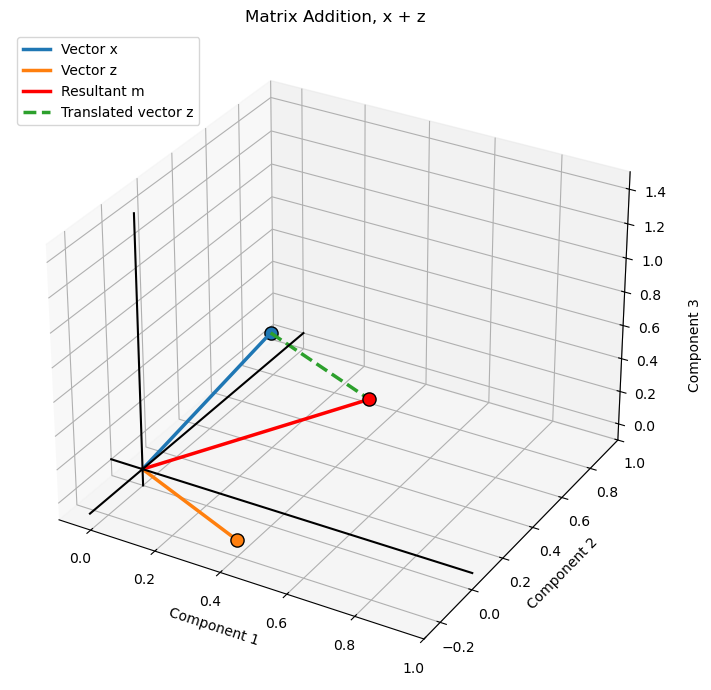

In [253]:
m = x + z                                                     # matrix addition

fig = plt.figure(figsize=(8, 7))                              # 3D visualization of vector addition
ax = fig.add_subplot(111, projection='3d')

vectors = [x, z, m]
colors = ['tab:blue', 'tab:orange', 'red']
labels = ['Vector x', 'Vector z', 'Resultant m']

for vec, color, label in zip(vectors, colors, labels):
    ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]],color=color, linewidth=2.5, label=label)
    ax.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=90, zorder=3)

ax.plot([x[0], m[0]], [x[1], m[1]], [x[2], m[2]],color='tab:green', linewidth=2.5, linestyle='--',label='Translated vector z') # z translated to the head of x

format_3d_plot(ax, 0.95,"Matrix Addition, x + z",True)               # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Vector Subtraction

Vector subtraction subtracts the corresponding components of one vector from another to produce a new vector representing their difference.

$$
\bf m = \bf x - \bf z = \begin{bmatrix} x_1-z_1 \\ x_2-z_2 \\ \vdots \\ x_n-z_n \end{bmatrix}
$$

Using our example vectors:

$$
\bf m = \bf x - \bf z = \begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix} - \begin{bmatrix} 0.40 \\ -0.20 \\ 0.00 \end{bmatrix} =
\begin{bmatrix} -0.20 \\ 0.60 \\ 0.60 \end{bmatrix}
$$

The geometric interpretation is similar to vector addition, except the second vector is reversed. Subtracting a vector is equivalent to adding its negative, so the resultant vector can be constructed using the head-to-tail method.

$$
\bf x - \bf z = \bf x + (-\bf z)
$$

Uses of vector subtraction in machine learning include:

- **Prediction errors** – calculate the difference between observed and predicted values to form a residual or error vector.

- **Gradient-based optimization** – subtract a scaled gradient vector from model parameters to update them during gradient descent.

- **Distance calculations** – subtract feature vectors before calculating Euclidean distance to measure dissimilarity between observations.

- **Anomaly detection** – calculate the difference between observed and reconstructed feature vectors to identify unusual observations.

- **Embedding comparisons** – subtract embedding vectors to represent differences between words, documents, or other learned representations.

- **Residual connections** – compare input and transformed representations to examine how a neural network layer changes information.

- **Vector decomposition** – subtract a projected component from an original vector to isolate the remaining component, such as the orthogonal residual.

Let's calculate and visualize vector subtraction over the 3D space of the vectors.

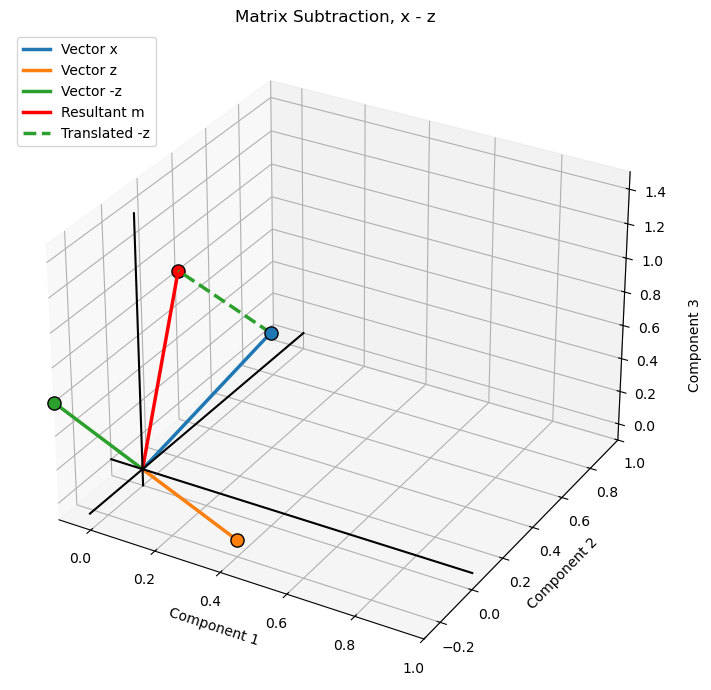

In [254]:
m = x - z                                                     # matrix subtraction

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

vectors = [x, z, -z, m]                                       # original vectors and resultant
colors = ['tab:blue', 'tab:orange', 'tab:green', 'red']
labels = ['Vector x', 'Vector z','Vector -z', 'Resultant m']

for vec, color, label in zip(vectors, colors, labels):
    ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]],color=color, linewidth=2.5, label=label)
    ax.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=90, zorder=3)

ax.plot([x[0], m[0]], [x[1], m[1]], [x[2], m[2]],color='tab:green', linewidth=2.5, linestyle='--',label='Translated -z') # head of x to head of m

format_3d_plot(ax, 0.95, "Matrix Subtraction, x - z",True)            # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Scalar-vector Multiplication

Scalar-vector multiplication multiplies every component of a vector by a scalar factor, changing its magnitude while preserving its direction for a positive scalar.

$$
\bf m = s\bf x =
\begin{bmatrix}
sx_1 \\
sx_2 \\
\vdots \\
sx_n
\end{bmatrix}
$$

Using a scalar factor of $s=2$ and our example vector:

$$
\bf m = 2\bf x =
2
\begin{bmatrix}
0.20 \\ 0.40 \\ 0.60
\end{bmatrix}
=
\begin{bmatrix}
0.40 \\ 0.80 \\ 1.20
\end{bmatrix}
$$

The scalar factor changes the vector's magnitude by a factor of $|s|$. A positive scalar preserves its direction, while a negative scalar reverses its direction.

Uses of scalar-vector multiplication in machine learning include:

- **Linear models** – multiply feature vectors or model coefficients by scalar weights when calculating predictions.
  
- **Gradient-based optimization** – multiply gradient vectors by the learning rate to determine the magnitude of parameter updates.

- **Regularization** – scale model weight vectors or penalty terms to control their contribution to an objective function.

- **Ensemble learning** – multiply individual model prediction vectors by scalar weights when combining predictions.

- **Attention mechanisms** – scale query-key dot products before applying softmax in scaled dot-product attention.

- **Vector normalization** – multiply a vector by the reciprocal of its magnitude to produce a unit vector.

- **Embedding transformations** – scale embedding vectors to adjust their magnitude while preserving their direction.

Let's calculate and visualize scalar-vector multiplication over the 3D space of the vectors.

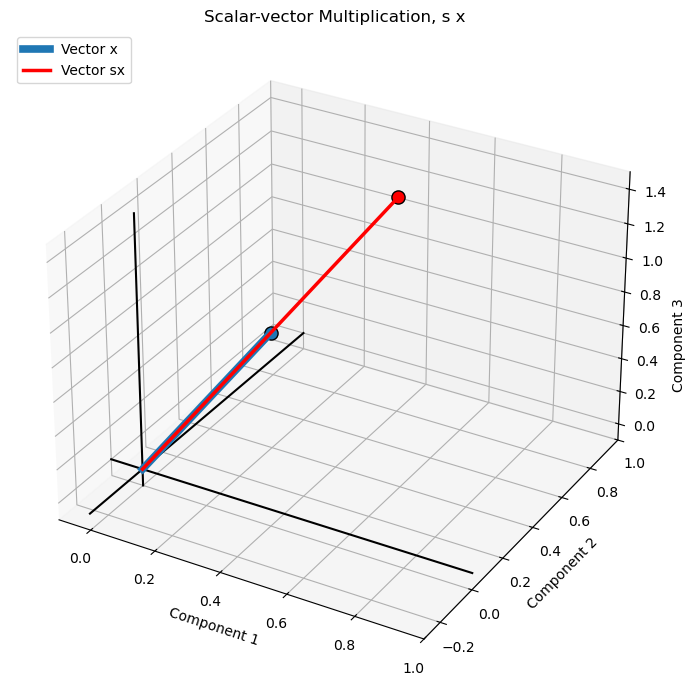

In [255]:
s = 2.0                                                       # scalar multiplication factor
xs = s * x                                                    # scalar-vector multiplication

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot([0, x[0]], [0, x[1]], [0, x[2]],color='tab:blue', linewidth=5.5, label='Vector x',zorder=4) # original vector x
ax.scatter(x[0], x[1], x[2], color='tab:blue',edgecolor='black', s=90,zorder=3)

ax.plot([0, xs[0]], [0, xs[1]], [0, xs[2]],color='red', linewidth=2.5, label='Vector sx',zorder=7) # scaled vector xs
ax.scatter(xs[0], xs[1], xs[2], color='red',edgecolor='black', s=90,zorder=10)

format_3d_plot(ax, 0.93, "Scalar-vector Multiplication, s x",True) # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Convex Linear Vector Combination

A convex combination is a linear combination in which the scalar coefficients are nonnegative and sum to one, producing a weighted average of the input vectors.

$$
\bf m = a\bf x + b\bf z
$$

where,

$$
a \geq 0,\quad b \geq 0,\quad a+b=1
$$

Using our example vectors, with $a=0.25$ and $b=0.75$:

$$
\bf m = 0.25\bf x + 0.75\bf z
$$

$$
=0.25 \begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix} + 0.75 \begin{bmatrix} 0.40 \\ -0.20 \\ 0.00 \end{bmatrix} =
\begin{bmatrix} 0.35 \\ -0.05 \\ 0.15 \end{bmatrix}
$$

Convex combinations are used in weighted averaging, interpolation, ensemble learning, and mixture models.

Note, 

* when the scalar coefficients are nonnegative and sum to one, the linear combination is called a **convex combination**

* otherwise, if the scalar coefficient include negatives or do not sum to one, it is a general linear combination.

Geometric interpretation: 

* the scaled vectors are placed head-to-tail. The resultant m extends from the origin to the endpoint of the second scaled vector. Because the coefficients are positive and sum to one, the resultant lies between the original vectors.

Uses of convex linear combinations in machine learning include:

- **Ensemble learning** – combine predictions from multiple models using nonnegative weights that sum to one, producing a weighted average.
  
- **Attention mechanisms** – combine value vectors using attention weights generated by softmax, which are nonnegative and sum to one.

- **Mixture models** – combine component distributions or model outputs using mixture weights that sum to one.

- **Embedding combinations** – combine multiple feature or embedding vectors using normalized weights to create a weighted representation.

- **Interpolation** – generate intermediate feature vectors or predictions between observations or representations.

- **Data augmentation** – create synthetic training examples by taking weighted averages of existing observations.

- **Probabilistic predictions** – combine probability distributions while preserving nonnegative values and a sum of one.

Let's calculate and visualize convex linear vector combination over the 3D space of the vectors.

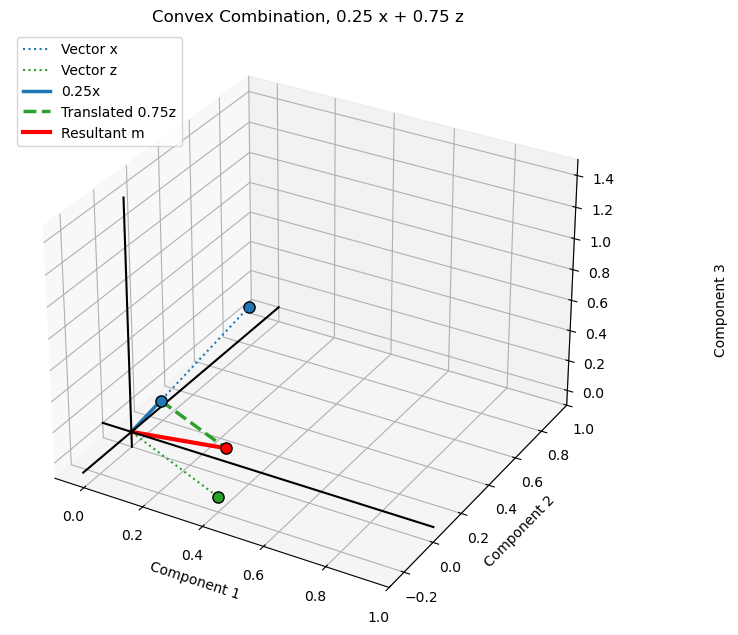

In [256]:
a = 0.25                                                      # scalar coefficient for x
b = 0.75                                                      # scalar coefficient for z

m = a * x + b * z                                             # linear combination

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.set_title('Convex Combination: 0.25x + 0.75z')

ax.plot([0, x[0]], [0, x[1]], [0, x[2]],color='tab:blue', linewidth=1.5, linestyle=':',label='Vector x') # original vectors
ax.plot([0, z[0]], [0, z[1]], [0, z[2]],color='tab:green', linewidth=1.5, linestyle=':',label='Vector z')

ax.plot([0, a*x[0]], [0, a*x[1]], [0, a*x[2]],color='tab:blue', linewidth=2.5,label='0.25x') # scaled vector a*x
ax.plot([a*x[0], m[0]], [a*x[1], m[1]], [a*x[2], m[2]],color='tab:green', linewidth=2.5, linestyle='--',label='Translated 0.75z') # scaled vector b*z, translated to head of a*x
ax.plot([0, m[0]], [0, m[1]], [0, m[2]],color='red', linewidth=3,label='Resultant m') # resultant vector

for vec, color in [(x, 'tab:blue'), (z, 'tab:green'),(a*x, 'tab:blue'), (m, 'red')]: # mark endpoints
    ax.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=65, zorder=3)

format_3d_plot(ax, 0.88,"Convex Combination, 0.25 x + 0.75 z", True)          # add axis labels, origin lines and legend

fig.subplots_adjust(left=0.02, right=0.82, bottom=0.05, top=0.90); plt.show()

#### General Linear Vector Combination

A general linear vector combination combines two or more vectors using scalar coefficients that can be any real numbers, including negative values. Unlike a convex combination, the coefficients do not need to be nonnegative or sum to one.

$$
\bf m = a\bf x + b\bf z
$$

Using our example vectors, we calculate a general linear combination with $a=1.5$ and $b=0.5$:

$$
\bf m = 1.5\bf x + 0.5\bf z
$$

$$
= 1.5 \begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix} + 0.5 \begin{bmatrix} 0.40 \\ -0.20 \\ 0.00 \end{bmatrix}
= \begin{bmatrix} 0.50 \\ 0.50 \\ 0.90 \end{bmatrix}
$$

The coefficients in this example sum to two, so the result is not a weighted average. General linear combinations are fundamental to linear regression, feature transformations, neural network layers, and representing vectors using a set of basis vectors.

When the coefficients sum to one but include negative values, the combination is more specifically called an **affine combination**.

General observations, 

* in the convex example, the resultant lies between the two original vector endpoints. 
    
* in the general linear example, the resultant extends beyond that region because the coefficients sum to two.

The head-to-tail construction is identical in both plots; only the scalar coefficients change.

Uses of general linear combinations in machine learning include:

- **Linear regression** – calculate predictions as weighted sums of input features, where coefficients can be positive or negative and do not need to sum to one.
  
- **Neural networks** – combine input signals or neuron outputs using learned weights, allowing flexible scaling and cancellation of contributions.

- **Feature transformations** – construct new features by combining existing feature vectors using arbitrary scalar coefficients.

- **Principal Component Analysis (PCA)** – represent observations as linear combinations of principal component directions.

- **Embedding transformations** – combine embedding vectors with learned coefficients to represent relationships or transformations in an embedding space.

- **Gradient-based optimization** – combine gradient and update vectors to determine changes in model parameters.

- **Signal processing** – represent signals as weighted combinations of basis vectors or functions.

Let's calculate and visualize general linear vector combination over the 3D space of the vectors.

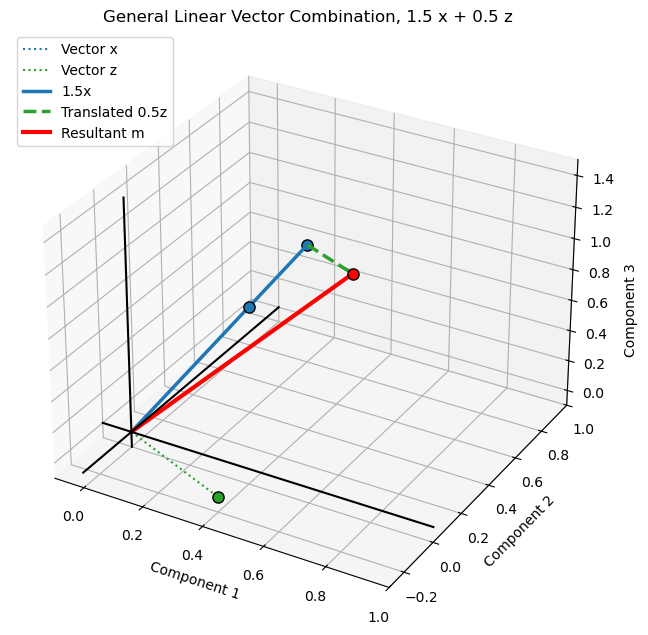

In [257]:
a = 1.5                                                       # scalar applied to x vector
b = 0.5                                                       # scalar applied to z vector

m = a * x + b * z                                             # general linear vector combination

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.set_title('General Linear Combination: 1.5x + 0.5z')

ax.plot([0, x[0]], [0, x[1]], [0, x[2]],color='tab:blue', linewidth=1.5, linestyle=':',label='Vector x') # original vectors
ax.plot([0, z[0]], [0, z[1]], [0, z[2]],color='tab:green', linewidth=1.5, linestyle=':',label='Vector z')

ax.plot([0, a*x[0]], [0, a*x[1]], [0, a*x[2]],color='tab:blue', linewidth=2.5, label='1.5x') # scaled vectors and head-to-tail construction
ax.plot([a*x[0], m[0]], [a*x[1], m[1]], [a*x[2], m[2]],color='tab:green', linewidth=2.5, linestyle='--',label='Translated 0.5z')

ax.plot([0, m[0]], [0, m[1]], [0, m[2]],color='red', linewidth=3, label='Resultant m') # resultant vector

for vec, color in [(x, 'tab:blue'), (z, 'tab:green'),(a*x, 'tab:blue'), (m, 'red')]: # mark endpoints
    ax.scatter(vec[0], vec[1], vec[2], color=color,edgecolor='black', s=65, zorder=3)

format_3d_plot(ax, 0.78, "General Linear Vector Combination, 1.5 x + 0.5 z",True)    # add axis labels, origin lines and legend

fig.subplots_adjust(left=0.02, right=0.82, bottom=0.05, top=0.90)
plt.show()

#### Vector Norms

A vector norm is a function that measures the magnitude or size of a vector. Different norms provide different ways to measure vector magnitude and are useful in machine learning for measuring prediction errors, regularization, and distances.

##### L1 Norm (Manhattan Norm)

The L1 norm measures vector magnitude as the sum of the absolute values of its components.

$$
\|\bf x\|_1 = \sum_{i=1}^{n}|x_i|
$$

##### L2 Norm (Euclidean Norm)

The L2 norm measures vector magnitude as the square root of the sum of squared components. This is the familiar Euclidean length of a vector.

$$
\|\bf x\|_2 = \sqrt{\sum_{i=1}^{n}x_i^2}
$$

##### L-infinity Norm (Maximum Norm)

The L-infinity norm measures vector magnitude as the largest absolute value among its components.

$$
\|\bf x\|_\infty = \max_i |x_i|
$$

Note, 

* the L2 norm is exactly the vector magnitude we have already introduced. The other norms measure size differently.

Uses of vector norms in machine learning include:

- **Prediction error** – calculate L1 or L2 norms of residual vectors to summarize the overall magnitude of prediction errors.
  
- **Regularization** – penalize model parameters using L1 norms (Lasso) to encourage sparsity or squared L2 norms (Ridge) to discourage large coefficients.

- **Distance-based learning** – use L1, L2, or other norms to measure distances between observations for clustering and nearest neighbor algorithms.

- **Gradient monitoring** – measure gradient vector norms to monitor optimization and identify exploding or vanishing gradients.

- **Weight constraints** – constrain the norms of model weight vectors, such as with max-norm regularization, to control parameter magnitudes.

- **Robust optimization** – use different norms to define uncertainty sets and control how model predictions respond to perturbations.

- **Feature normalization** – use vector norms to scale feature vectors, including L1 and L2 normalization, to control their magnitude.

- **Anomaly detection** – use residual or reconstruction-error norms to identify observations with unusually large deviations from model expectations.

Let's calculate and visualize vector norms over the 3D space of the vectors.

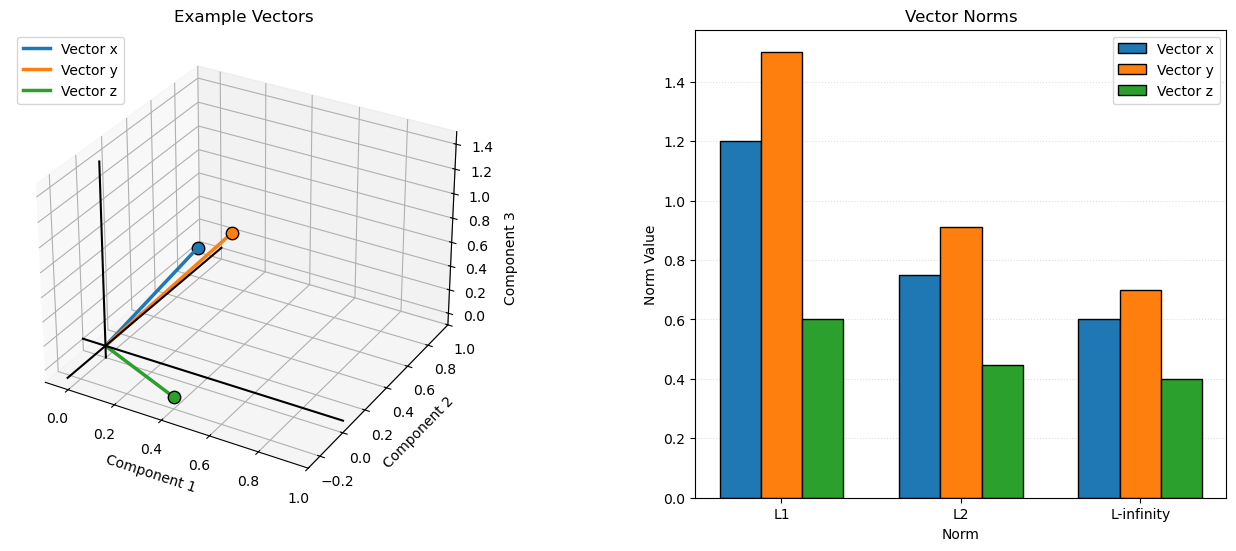

In [258]:
vectors = [x, y, z]                                           # calculate norms for each vector
vector_names = ['x', 'y', 'z']
vector_colors = ['tab:blue', 'tab:orange', 'tab:green']

norm_names = ['L1', 'L2', 'L-infinity']
norm_orders = [1, 2, np.inf]

norm_values = np.array([[np.linalg.norm(v, ord=order) for v in vectors] for order in norm_orders])

fig = plt.figure(figsize=(13, 6))                             # create side-by-side plots

ax1 = fig.add_subplot(121, projection='3d')                   # left: 3D vector plot
ax1.set_title('Example Vectors')

for v, name, color in zip(vectors, vector_names, vector_colors):
    ax1.plot([0, v[0]], [0, v[1]], [0, v[2]],color=color, linewidth=2.5, label=f'Vector {name}')
    ax1.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

format_3d_plot(ax1, 0.43, "Example Vectors",True)             # add axis labels, origin lines and legend

ax2 = fig.add_subplot(122)                                    # right: grouped bar chart of vector norms
ax2.set_title('Vector Norms')

n_norms = len(norm_names)
n_vectors = len(vector_names)
bar_width = 0.23
positions = np.arange(n_norms)

for i, (name, color) in enumerate(zip(vector_names, vector_colors)):
    ax2.bar(positions + (i - 1) * bar_width,norm_values[:, i],width=bar_width,color=color,edgecolor='black',label=f'Vector {name}')

ax2.set_xticks(positions); ax2.set_xticklabels(norm_names); ax2.set_ylabel('Norm Value'); ax2.set_xlabel('Norm')
ax2.grid(axis='y', linestyle=':', alpha=0.4); ax2.set_axisbelow(True); ax2.legend()

fig.subplots_adjust(left=0.02, right=0.98,bottom=0.10, top=0.88, wspace=0.35); plt.show()

#### Vector Dot Product

The dot product multiplies corresponding components of two vectors and sums the products to produce a scalar. It measures how much two vectors are aligned and is used extensively in machine learning for weighted sums, similarity calculations, and projections.

$$
\bf{x} \cdot \bf{y} = \sum_{i=1}^{n} x_i y_i
$$

For two three-dimensional vectors:

$$
\bf{x} \cdot \bf{y} =
x_1y_1+x_2y_2+x_3y_3
$$

The dot product is also related to the angle between two vectors:

$$
\bf{x} \cdot \bf{y} =
\|\bf{x}\|_2 \|\bf{y}\|_2 \cos(\theta)
$$

This is how we calculate the angle between two nonzero vectors using their dot product and L2 norms,

$$
\cos(\theta) = \frac{\bf x \cdot \bf y}{\|\bf x\|_2 \|\bf y\|_2}
$$

$$
\theta = \cos^{-1}\left(\frac{\bf x \cdot \bf y}{\|\bf x\|_2 \|\bf y\|_2}\right)
$$

where $\theta$ is the angle between the vectors, and $\|\bf{x}\|_2$ and $\|\bf{y}\|_2$ are their L2 norms.

Using our example vectors:

$$
\bf{x} \cdot \bf{y} =
(0.20)(0.30)+(0.40)(0.50)+(0.60)(0.70)
=0.68
$$

$$
\bf{x} \cdot \bf{z} =
(0.20)(0.40)+(0.40)(-0.20)+(0.60)(0.00)
=0.00
$$

Dot product indicates the alignment of two vectors,

* a positive dot product indicates an angle less than 90 degrees

*  a zero dot product indicates orthogonal vectors (90 degrees)

*  a negative dot product indicates an angle greater than 90 degrees.

Uses of the vector dot product in machine learning include:

- **Cosine similarity** – calculate the directional similarity between feature vectors or embeddings, widely used in information retrieval and semantic search.

- **Linear regression** – calculate predictions as the dot product of feature vectors and model coefficients.

- **Neural networks** – calculate weighted sums of inputs and model weights within artificial neurons.

- **Attention mechanisms** – calculate query-key dot products to measure relationships between elements in a sequence.

- **Vector projection** – calculate the component of one vector aligned with another, useful in dimensionality reduction and geometric analysis.

- **Feature alignment** – measure how strongly an observation or feature vector aligns with a particular direction or learned representation.

- **Optimization** – calculate directional derivatives and assess how a gradient aligns with a proposed parameter update.

- **Kernel methods** – use dot products to represent similarity between observations in linear kernel algorithms such as support vector machines.

Let's calculate and visualize vector dot product over the 3D space of the vectors.

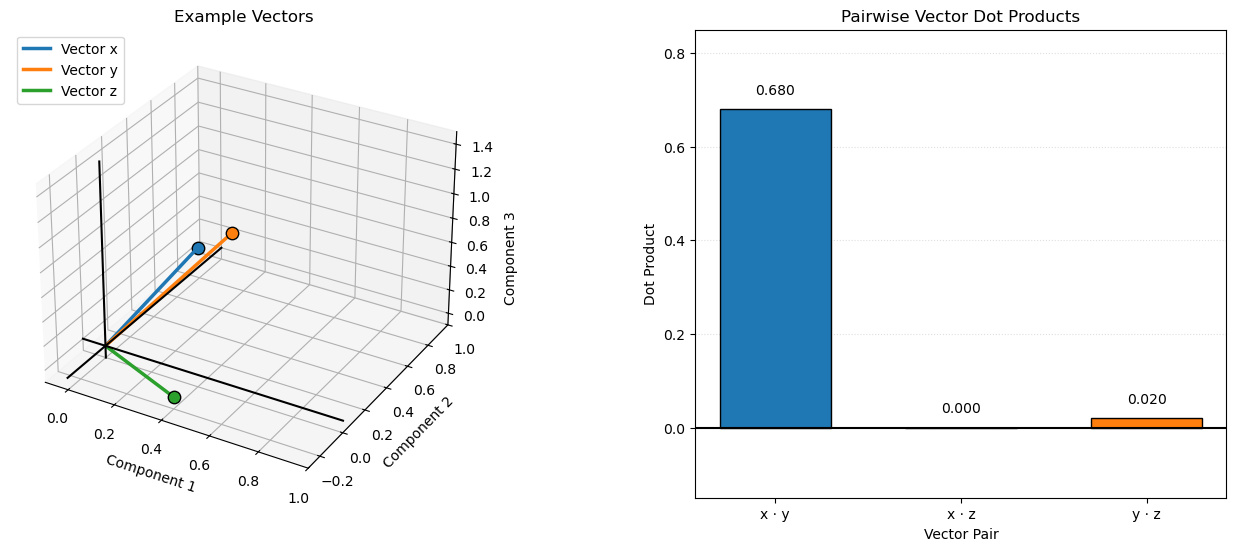

In [259]:
dot_products = [np.dot(x, y),np.dot(x, z),np.dot(y, z)]       # calculate pairwise dot products

vectors = [x, y, z]                                           # update vectors for visualization
vector_names = ['x', 'y', 'z']
vector_colors = ['tab:blue', 'tab:orange', 'tab:green']

pair_names = ['x · y', 'x · z', 'y · z']
pair_colors = ['tab:blue', 'tab:green', 'tab:orange']

fig = plt.figure(figsize=(13, 6))                              

ax1 = fig.add_subplot(121, projection='3d')                   # left: 3D vector plot

for v, name, color in zip(vectors, vector_names, vector_colors):
    ax1.plot([0, v[0]], [0, v[1]], [0, v[2]],color=color, linewidth=2.5, label=f'Vector {name}')
    ax1.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

format_3d_plot(ax1, 0.43, "Example Vectors",True)             # add axis labels, origin lines and legend

ax2 = fig.add_subplot(122)                                    # right: pairwise dot product bar chart
ax2.set_title('Pairwise Vector Dot Products')

bars = ax2.bar(pair_names, dot_products,
               color=pair_colors, edgecolor='black',
               width=0.6)

ax2.axhline(0, color='black', linewidth=1.5)                  # zero reference line

for bar, value in zip(bars, dot_products):                    # add numerical values above/below bars
    offset = 0.025 if value >= 0 else -0.025
    ax2.text(bar.get_x() + bar.get_width()/2,value + offset, f'{value:.3f}',ha='center',va='bottom' if value >= 0 else 'top')

ax2.set_ylabel('Dot Product'); ax2.set_xlabel('Vector Pair'); ax2.set_ylim(-0.15, 0.85); ax2.grid(axis='y', linestyle=':', alpha=0.4)
ax2.set_axisbelow(True)

fig.subplots_adjust(left=0.02, right=0.98,bottom=0.10, top=0.88, wspace=0.35); plt.show()

#### Vector Cosine Similarity

Cosine similarity measures the directional similarity between two vectors by calculating the cosine of the angle between them. It ranges from -1 to 1, where 1 indicates vectors pointing in the same direction, 0 indicates orthogonal vectors, and -1 indicates vectors pointing in opposite directions.

$$
\text{Cosine Similarity}(\bf x,\bf y) =
\frac{\bf x \cdot \bf y}
{\|\bf x\|_2 \|\bf y\|_2}
$$

Using our example vectors:

$$
\text{Cosine Similarity}(\bf x,\bf y) =
\frac{0.68}{\sqrt{0.56}\sqrt{0.83}}
\approx 0.996
$$

$$
\text{Cosine Similarity}(\bf x,\bf z) =
\frac{0.00}{\sqrt{0.56}\sqrt{0.20}}
= 0.00
$$

Cosine similarity is widely used in machine learning for comparing feature vectors, document embeddings, and other high-dimensional representations. Unlike the dot product, cosine similarity is independent of vector magnitude and focuses on direction.

Uses of vector cosine similarity in machine learning include:

- **Semantic search** – compare text embeddings to retrieve documents or passages with similar meanings.

- **Recommendation systems** – compare user and item embeddings to identify products, content, or services with similar preference representations.

- **Document classification** – compare document feature vectors to identify documents with similar content or topics.

- **Clustering** – group observations based on the directional similarity of their feature or embedding vectors.

- **Image recognition** – compare image embeddings to identify visually or semantically similar images.

- **Information retrieval** – rank search results by their similarity to a query embedding.

- **Anomaly detection** – identify observations whose feature or embedding directions differ substantially from typical observations.

- **Duplicate detection** – identify similar text, documents, or images using their vector representations.

Let's calculate and visualize vector cosine similarity over the 3D space of the vectors.

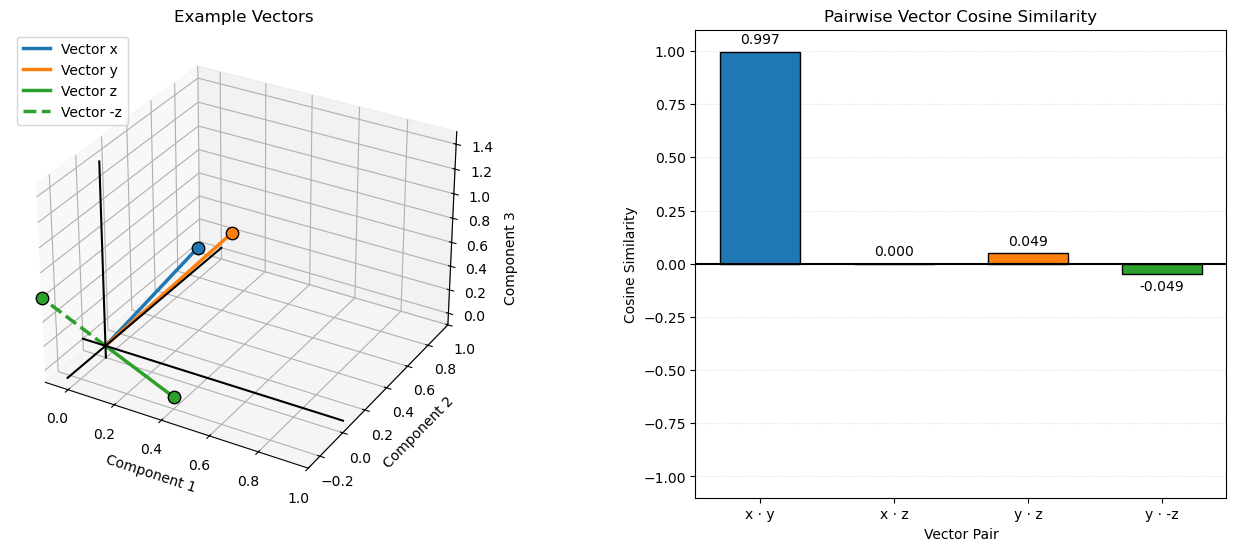

In [260]:
neg_z = -z                                                    # define negative z vector

vectors = [x, y, z, neg_z]                                    # update vectors for visualization
vector_names = ['x', 'y', 'z', '-z']
vector_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:green']

cosine_similarities = [                                       # calculate pairwise cosine similarities
    np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y)),
    np.dot(x, z) / (np.linalg.norm(x) * np.linalg.norm(z)),
    np.dot(y, z) / (np.linalg.norm(y) * np.linalg.norm(z)),
    np.dot(y, neg_z) / (np.linalg.norm(y) * np.linalg.norm(neg_z))
]

pair_names = ['x · y', 'x · z', 'y · z', 'y · -z']
pair_colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:green']

fig = plt.figure(figsize=(13, 6))                             # create side-by-side plots
 
ax1 = fig.add_subplot(121, projection='3d')                   # left: 3D vector plot

for v, name, color in zip(vectors, vector_names, vector_colors):
    linestyle = '--' if name == '-z' else '-'
    ax1.plot([0, v[0]], [0, v[1]], [0, v[2]],color=color, linewidth=2.5, linestyle=linestyle,label=f'Vector {name}')
    ax1.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

format_3d_plot(ax1, 0.43, "Example Vectors",True)             # add axis labels, origin lines and legend

ax2 = fig.add_subplot(122)                                    # right: pairwise cosine similarity bar chart
ax2.set_title('Pairwise Vector Cosine Similarity')

bars = ax2.bar(pair_names, cosine_similarities,
               color=pair_colors, edgecolor='black',
               width=0.6)

ax2.axhline(0, color='black', linewidth=1.5)                  # zero reference line

for bar, value in zip(bars, cosine_similarities):             # add numerical values above/below bars
    offset = 0.025 if value >= 0 else -0.025
    ax2.text(bar.get_x() + bar.get_width()/2,value + offset, f'{value:.3f}',ha='center',va='bottom' if value >= 0 else 'top')

ax2.set_ylabel('Cosine Similarity'); ax2.set_xlabel('Vector Pair'); ax2.set_ylim(-1.1, 1.1)
ax2.set_yticks(np.arange(-1.0, 1.01, 0.25)); ax2.grid(axis='y', linestyle=':', alpha=0.4); ax2.set_axisbelow(True)

fig.subplots_adjust(left=0.02, right=0.98,bottom=0.10, top=0.88, wspace=0.35); plt.show()

#### Matrix

A matrix is a rectangular arrangement of numbers organized into rows and columns. Matrices are used in linear algebra and machine learning to organize data, represent relationships between variables, and perform transformations.

A matrix with $n$ rows and $m$ columns has dimensions $n \times m$.

Let's visualize our example matrices, $\bf{A}$, $\bf{B}$ and $\bf{I}$.

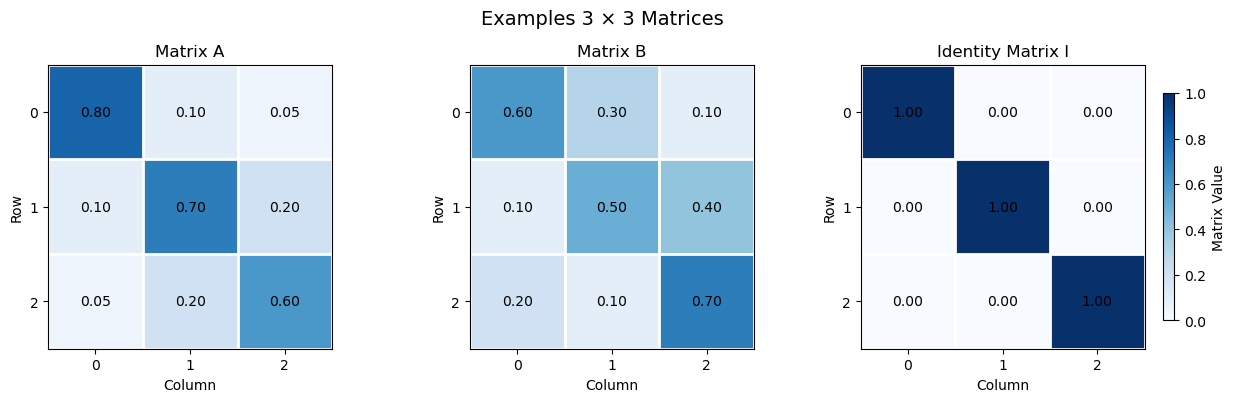

In [261]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))                      # visualize matrices

matrices = [A, B, I]
matrix_names = ['Matrix A', 'Matrix B', 'Identity Matrix I']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    plot_matrix(ax,matrix,name)
    
cbar = fig.colorbar(im, ax=axes[2], shrink=0.8, pad=0.05); cbar.set_label('Matrix Value')
fig.suptitle('Examples 3 × 3 Matrices', fontsize=14)

plt.tight_layout(); plt.show()

#### Matrix Dimensions

The dimensions of a matrix describe its number of rows and columns. A matrix with $m$ rows and $n$ columns has dimensions $m \times n$, where $m$ is the number of rows and $n$ is the number of columns.

For our example matrices:

$$
\bf A_{3 \times 3}, \quad
\bf B_{3 \times 3}, \quad
\bf I_{3 \times 3}
$$

All three matrices have 3 rows and 3 columns. The dimensions determine which matrix operations are possible. For example, 

* matrix multiplication requires the number of columns in the first matrix to equal the number of rows in the second matrix.

Uses of matrix dimensions in machine learning include:

- **Data representation** – describe the number of observations (rows) and features (columns) in a dataset.

- **Dimension compatibility** – determine whether matrix addition and multiplication operations are mathematically valid.

- **Neural network architecture** – define the number of input features, hidden units, and output units in network layers.

- **Model parameters** – determine the dimensions of weight matrices and bias vectors in predictive models.

- **Dimensionality reduction** – describe changes in the number of features when transforming data using methods such as PCA.

- **Batch processing** – represent the number of observations processed together and the number of features supplied to a model.

- **Matrix factorization** – define the dimensions of lower-rank matrices used in SVD, PCA, and recommendation systems.

The .shape member function is available to recover the shape of any metric or vector with NumPy Python package.

In [262]:
print('Dimensions of A:', A.shape)                            # display matrix dimensions
print('Dimensions of B:', B.shape)
print('Dimensions of I:', I.shape)

Dimensions of A: (3, 3)
Dimensions of B: (3, 3)
Dimensions of I: (3, 3)


#### Matrix Transpose

The transpose of a matrix is formed by switching its rows and columns. Each row of the original matrix becomes a column in the transposed matrix, and each column becomes a row.

For a matrix $\bf A$ with dimensions $n \times m$, its transpose, $\bf A^T$, has dimensions $m \times n$.

$$
\bf A^T_{j,i} = \bf A_{i,j}
$$

Using our example matrix:

$$
\bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

$$
\bf A^T =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

Since $\bf A$ is symmetric, its transpose is equal to the original matrix. In contrast, $\bf B$ is asymmetric, so its transpose is different.

Uses of matrix transpose in machine learning are ubiquious, including:

- **Linear regression** – form the normal equations using the transpose of the feature matrix when calculating least squares solutions.

- **Neural networks** – propagate gradients backward through network layers using transposed weight matrices.

- **Matrix multiplication** – rearrange matrix dimensions to make operations dimensionally compatible.

- **Covariance calculations** – calculate covariance matrices using the transpose of a centered data matrix.

- **Singular Value Decomposition (SVD)** – use the transpose of a matrix to calculate singular values and relate left and right singular vectors.

- **PCA** – calculate covariance matrices and perform eigenvalue decomposition using a data matrix and its transpose.

- **Similarity calculations** – use transposed matrices to efficiently calculate pairwise dot products between observations or feature vectors.

Let's visualize our matrices and their transpose forms.

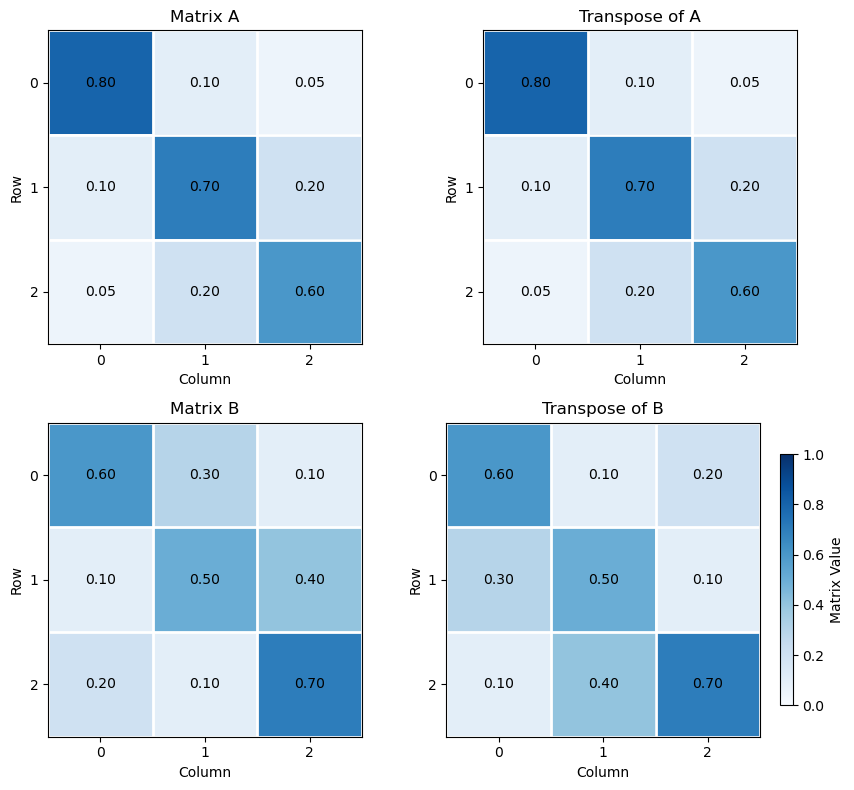

In [263]:
A_T = A.T                                                     # calculate matrix transposes
B_T = B.T

fig, axes = plt.subplots(2, 2, figsize=(9, 8))                # visualize original and transposed matrices

matrices = [A, A_T, B, B_T]
matrix_names = ['Matrix A', 'Transpose of A','Matrix B', 'Transpose of B']

for ax, matrix, name in zip(axes.flatten(), matrices, matrix_names):
    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[1, 1], label='Matrix Value', shrink=0.8)
plt.tight_layout(); plt.show()

#### Matrix Addition

Matrix addition combines two matrices by adding their corresponding elements. The matrices must have the same dimensions, and the resulting matrix has the same dimensions as the original matrices.

For two matrices $\bf A$ and $\bf B$:

$$
\bf C = \bf A + \bf B
$$

Each element of the resulting matrix is calculated as:

$$
c_{i,j} = a_{i,j} + b_{i,j}
$$

Using our example matrices:

$$
\bf C = \bf A + \bf B =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
+
\begin{bmatrix}
0.60 & 0.30 & 0.10 \\
0.10 & 0.50 & 0.40 \\
0.20 & 0.10 & 0.70
\end{bmatrix}
$$

$$
=
\begin{bmatrix}
1.40 & 0.40 & 0.15 \\
0.20 & 1.20 & 0.60 \\
0.25 & 0.30 & 1.30
\end{bmatrix}
$$

Uses of matrix addition in machine learning include:

- **Neural networks** – add bias vectors to weighted input matrices to calculate neuron activations.

- **Residual connections** – add the input of a network layer to its transformed output to improve information and gradient flow through deep networks.

- **Ensemble learning** – combine prediction matrices from multiple models, often using weighted sums or averages.

- **Gradient-based optimization** – add parameter update matrices to current model weight matrices during training.

- **Covariance estimation** – add covariance or regularization matrices to improve numerical stability in statistical models.

- **Data augmentation** – add noise matrices to input data to generate perturbed training examples.

- **Matrix factorization** – combine matrix components or updates when reconstructing or refining matrix approximations.

Let's visualize our matrices and the matrix addition demonstrated above.

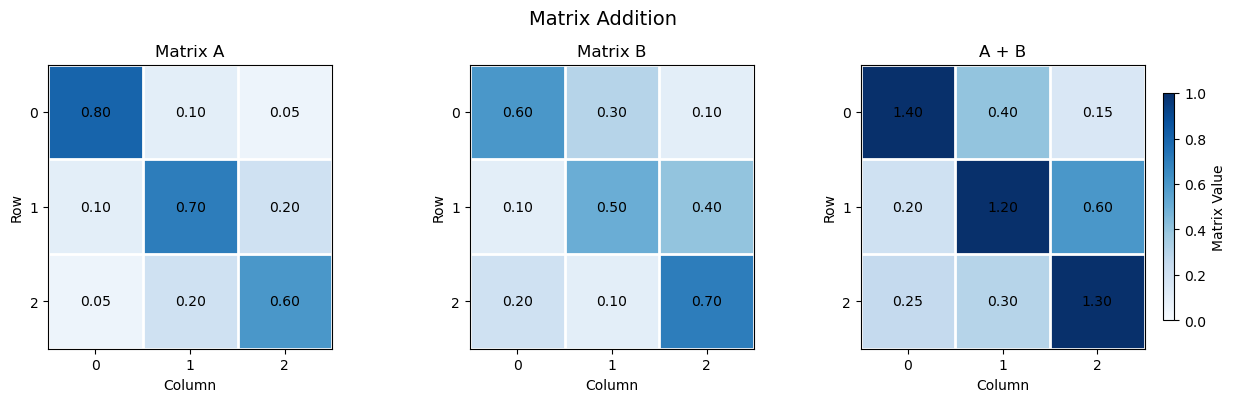

In [264]:
C = A + B                                                     # matrix addition

fig, axes = plt.subplots(1, 3, figsize=(13, 4))               # visualize matrices A, B, and their sum C

matrices = [A, B, C]
matrix_names = ['Matrix A', 'Matrix B', 'A + B']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[2], label='Matrix Value', shrink=0.8); fig.suptitle('Matrix Addition', fontsize=14)

plt.tight_layout(); plt.show()

#### Matrix Scalar Multiplication

Matrix scalar multiplication multiplies every element of a matrix by a scalar value. The resulting matrix has the same dimensions as the original matrix, with each element scaled by the scalar.

For a matrix $\bf A$ and scalar $s$:

$$
\bf C = s\bf A
$$

Each element of the resulting matrix is calculated as:

$$
c_{i,j} = s a_{i,j}
$$

Using our example matrix and a scalar of $s=2$:

$$
\bf C = 2\bf A =
2
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

$$
=
\begin{bmatrix}
1.60 & 0.20 & 0.10 \\
0.20 & 1.40 & 0.40 \\
0.10 & 0.40 & 1.20
\end{bmatrix}
$$

Uses of matrix scalar multiplication in machine learning include:

- **Gradient-based optimization** – multiply gradient matrices by the learning rate to determine the magnitude of model parameter updates.

- **Regularization** – scale penalty terms in objective functions to control the strength of regularization.

- **Ensemble learning** – multiply prediction matrices by scalar weights when combining model outputs.

- **Neural networks** – scale weight matrices or activation values during model transformations and training.

- **Data normalization** – scale data matrices to adjust feature magnitudes and numerical ranges.

- **Attention mechanisms** – scale query-key score matrices before applying softmax in scaled dot-product attention.

- **Matrix decomposition** – scale matrix components or singular values when constructing low-rank approximations.

- **Learning rates** – multiply gradient matrices by a scalar learning rate to control the magnitude of weight updates during gradient-based optimization.

Let's visualize our matrices and the matrix scalar multiplication demonstrated above.

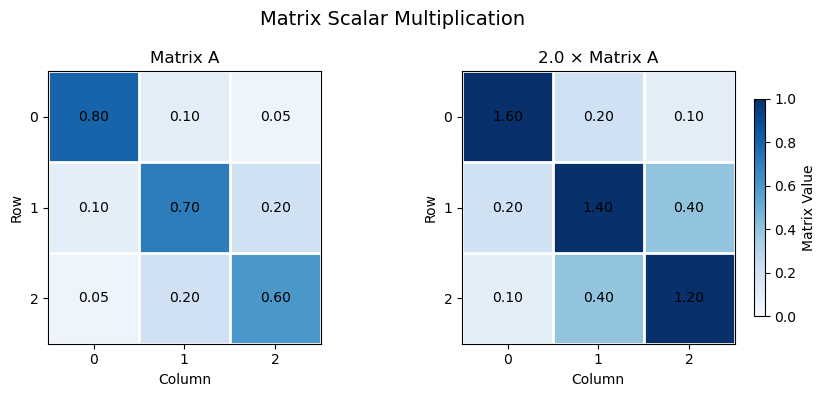

In [265]:
s = 2.0                                                       # define scalar

C = s * A                                                     # matrix scalar multiplication

fig, axes = plt.subplots(1, 2, figsize=(9, 4))                # visualize original and scaled matrices

matrices = [A, C]
matrix_names = ['Matrix A', f'{s:.1f} × Matrix A']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[1], label='Matrix Value', shrink=0.8); fig.suptitle('Matrix Scalar Multiplication', fontsize=14)

plt.tight_layout(); plt.show()

#### Matrix Element-wise Multiplication

Element-wise multiplication multiplies corresponding elements of two matrices to produce a new matrix. The matrices must have the same dimensions, and each element in the resulting matrix is the product of the corresponding elements in the original matrices.

For two matrices $\bf A$ and $\bf B$:

$$
\bf C = \bf A \odot \bf B
$$

Each element of the resulting matrix is calculated as:

$$
c_{i,j} = a_{i,j} b_{i,j}
$$

Using our example matrices:

$$
\bf C = \bf A \odot \bf B =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
\odot
\begin{bmatrix}
0.60 & 0.30 & 0.10 \\
0.10 & 0.50 & 0.40 \\
0.20 & 0.10 & 0.70
\end{bmatrix}
$$

$$
=
\begin{bmatrix}
0.48 & 0.03 & 0.005 \\
0.01 & 0.35 & 0.08 \\
0.01 & 0.02 & 0.42
\end{bmatrix}
$$

Element-wise multiplication is used in machine learning to apply masks, combine feature values, and perform gating operations in neural networks. For example, neural network gates use element-wise multiplication to control how much information passes through a model.

Note, element-wise multiplication is not matrix multiplication. In [NumPy](https://numpy.org/),

* A * B performs element-wise multiplication

* A @ B performs matrix multiplication.

Uses of element-wise multiplication in machine learning include:

- **Neural networks** – apply activation functions, gates, and masks through element-wise operations on matrices and vectors.

- **Attention mechanisms** – apply attention masks to score matrices to control which elements can contribute to attention.

- **Gradient calculations** – apply element-wise derivatives when calculating gradients through activation functions using the chain rule.

- **Feature weighting** – multiply feature matrices by element-wise weights to emphasize or suppress individual features.

- **Data masking** – multiply data matrices by binary masks to select, exclude, or control the contribution of individual elements.

- **Dropout regularization** – multiply neural network activations by randomly generated binary masks to temporarily deactivate selected neurons during training.

- **Image processing** – apply pixel-wise operations, masks, and weighting matrices to image data.

- **Covariance and correlation analysis** – combine corresponding matrix elements in element-wise calculations used in statistical analysis.

Let's visualize our matrices and the matrix element-wise multiplication demonstrated above.

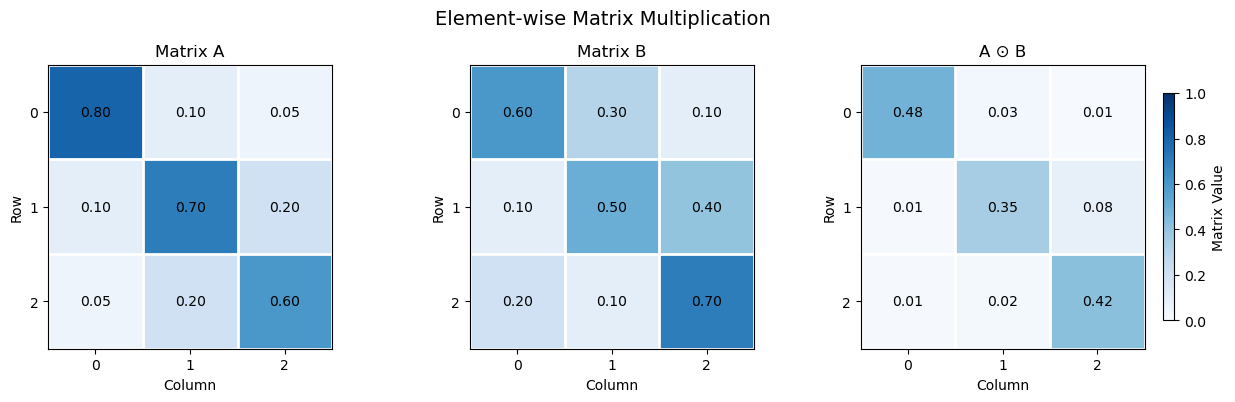

In [266]:
C = A * B                                                     # element-wise multiplication

fig, axes = plt.subplots(1, 3, figsize=(13, 4))               # visualize matrices A, B, and their element-wise product

matrices = [A, B, C]
matrix_names = ['Matrix A', 'Matrix B', 'A ⊙ B']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[2], label='Matrix Value', shrink=0.8); fig.suptitle('Element-wise Matrix Multiplication', fontsize=14)

plt.tight_layout(); plt.show()

#### Matrix-Vector Multiplication

Matrix-vector multiplication combines a matrix and a vector by calculating the dot product of each matrix row with the vector. The number of columns in the matrix must equal the number of elements in the vector.

For a matrix $\bf A$ with dimensions $n \times m$ and a vector $\bf x$ with $p$ elements, the resulting vector $\bf p$ has $n$ elements.

$$
\bf p = \bf A \bf x
$$

Each element of the resulting vector is calculated as:

$$
p_i = \sum_{j=1}^{m} a_{i,j}x_j
$$

Using our example matrix and vector:

$$
\bf p = \bf A \bf x =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
\begin{bmatrix}
0.20 \\ 0.40 \\ 0.60
\end{bmatrix}
$$

$$
= \begin{bmatrix} (0.80)(0.20)+(0.10)(0.40)+(0.05)(0.60) \\ (0.10)(0.20)+(0.70)(0.40)+(0.20)(0.60) \\ (0.05)(0.20)+(0.20)(0.40)+(0.60)(0.60) \end{bmatrix} = \begin{bmatrix} 0.23 \\ 0.42 \\ 0.45 \end{bmatrix}
$$

To check whether matrix and vector operations are dimensionally compatible, write the dimensions of each matrix or vector beside it. For multiplication, 

* the adjacent dimensions must match: the number of columns in the first matrix must equal the number of rows in the second matrix.

* the dimensions of the result are the two outer dimensions.

For our example:

$$
\underbrace{\bf A}_{3 \times 3} \underbrace{\bf x}_{3 \times 1} = \underbrace{\bf p}_{3 \times 1}
$$

The adjacent dimensions (3 and 3) match, so the multiplication is valid. The resulting vector has 3 rows and 1 column.

Matrix-vector multiplication is fundamental in machine learning. It is used to transform input features, calculate linear model predictions, and produce outputs from neural network layers.

Uses of matrix-vector multiplication in machine learning include:

- **Linear regression** – multiply a feature matrix by a coefficient vector to calculate predictions for multiple observations.

- **Neural networks** – multiply layer weight matrices by input or activation vectors to calculate weighted sums of neuron inputs.

- **Linear transformations** – transform feature vectors into new representations using learned or predefined transformation matrices.

- **Dimensionality reduction** – project observations onto principal component directions in PCA.

- **Gradient-based optimization** – use matrix-vector products to calculate gradients and parameter updates in many optimization algorithms.

- **Graph neural networks** – aggregate information from neighboring nodes using adjacency or graph propagation matrices.

- **Recommender systems** – multiply user-item or latent-factor matrices by vectors to calculate predicted preferences or ratings.

- **Scientific computing** – efficiently solve systems of linear equations that arise in statistical models and machine learning algorithms.

Let's visualize our matrices and the matrix-vector multiplication demonstrated above.

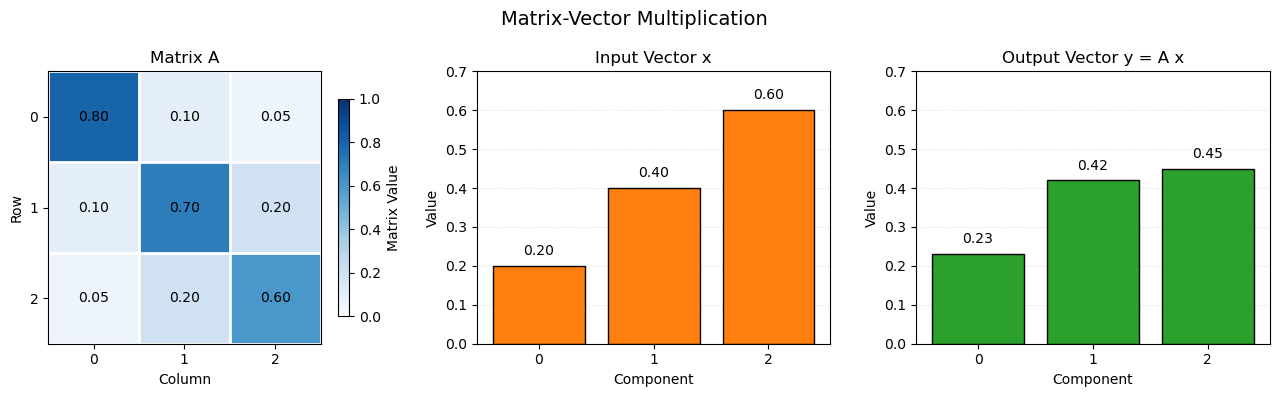

In [267]:
y = A @ x                                                     # matrix-vector multiplication

row_contributions = A * x                                     # calculate each row's dot product

fig, axes = plt.subplots(1, 3, figsize=(13, 4))               # visualize matrix A, vector x, and resulting vector y

plot_matrix(axes[0],A,"Matrix A")

axes[1].bar(np.arange(3), x, color='tab:orange', edgecolor='black') # input vector x
axes[1].set_title('Input Vector x'); axes[1].set_xlabel('Component'); axes[1].set_ylabel('Value')
axes[1].set_xticks(np.arange(3)); axes[1].set_ylim(0, 0.7); axes[1].grid(axis='y', linestyle=':', alpha=0.4)

axes[2].bar(np.arange(3), y, color='tab:green', edgecolor='black') # output vector y
axes[2].set_title('Output Vector y = A x'); axes[2].set_xlabel('Component'); axes[2].set_ylabel('Value')
axes[2].set_xticks(np.arange(3)); axes[2].set_ylim(0, 0.7); axes[2].grid(axis='y', linestyle=':', alpha=0.4)

for ax, values in zip(axes[1:], [x, y]):                      # annotate vector values
    for i, value in enumerate(values):
        ax.text(i, value + 0.02, f'{value:.2f}',
                ha='center', va='bottom')

fig.colorbar(im, ax=axes[0], label='Matrix Value', shrink=0.8); fig.suptitle('Matrix-Vector Multiplication', fontsize=14)

plt.tight_layout(); plt.show()

#### Matrix Multiplication

Matrix multiplication combines two matrices by multiplying the elements of each row in the first matrix by the corresponding elements of each column in the second matrix, then summing the products.

To check whether matrix multiplication is dimensionally compatible, write the dimensions of each matrix beside it. The adjacent dimensions must match: the number of columns in the first matrix must equal the number of rows in the second matrix. The dimensions of the result are the two outer dimensions.

For a matrix $\bf A$ with dimensions $m \times n$ and a matrix $\bf B$ with dimensions $n \times p$, the resulting matrix $\bf C$ has dimensions $m \times p$:

$$
\underbrace{\bf A}_{n \times m}
\underbrace{\bf B}_{m \times p}
=
\underbrace{\bf C}_{n \times p}
$$

Each element of the resulting matrix is calculated as the dot product of a row of $\bf A$ and a column of $\bf B$:

$$
c_{i,j} = \sum_{k=1}^{n} a_{i,k}b_{k,j}
$$

Using our example matrices:

$$
\underbrace{\bf C}_{3 \times 3}
=
\underbrace{\bf A}_{3 \times 3}
\underbrace{\bf B}_{3 \times 3}
$$

$$
\bf{C} =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
\begin{bmatrix}
0.60 & 0.30 & 0.10 \\
0.10 & 0.50 & 0.40 \\
0.20 & 0.10 & 0.70
\end{bmatrix}
$$

The individual elements of the resulting matrix are calculated by taking the dot product of each row of $\bf A$ with each column of $\bf B$:

$$
c_{1,1} = (0.80)(0.60)+(0.10)(0.10)+(0.05)(0.20) = 0.495
$$

$$
c_{1,2} = (0.80)(0.30)+(0.10)(0.50)+(0.05)(0.10) = 0.295
$$

$$
c_{1,3} = (0.80)(0.10)+(0.10)(0.40)+(0.05)(0.70) = 0.155
$$

$$
c_{2,1} = (0.10)(0.60)+(0.70)(0.10)+(0.20)(0.20) = 0.170
$$

$$
c_{2,2} = (0.10)(0.30)+(0.70)(0.50)+(0.20)(0.10) = 0.400
$$

$$
c_{2,3} = (0.10)(0.10)+(0.70)(0.40)+(0.20)(0.70) = 0.430
$$

$$
c_{3,1} = (0.05)(0.60)+(0.20)(0.10)+(0.60)(0.20) = 0.170
$$

$$
c_{3,2} = (0.05)(0.30)+(0.20)(0.50)+(0.60)(0.10) = 0.175
$$

$$
c_{3,3} = (0.05)(0.10)+(0.20)(0.40)+(0.60)(0.70) = 0.505
$$

Combining these nine calculated elements gives the resulting matrix:

$$
\bf C =
\begin{bmatrix}
0.495 & 0.295 & 0.155 \\
0.170 & 0.400 & 0.430 \\
0.170 & 0.175 & 0.505
\end{bmatrix}
$$

An important property is that matrix multiplication is generally not commutative:

$$
\bf AB \neq BA
$$

In other words, changing the order of the matrices generally changes the result.

Uses of matrix multiplication in machine learning include:

- **Neural networks** – multiply weight matrices by input or activation matrices to calculate outputs across multiple neurons and observations.

- **Linear regression** – calculate predictions for multiple observations using matrix multiplication of the feature matrix and coefficient vector.

- **Attention mechanisms** – multiply query and key matrices to calculate attention scores, and multiply attention weights by value matrices to combine information across sequence elements.

- **Dimensionality reduction** – transform datasets into lower-dimensional representations using projection matrices, as in PCA.

- **Covariance analysis** – calculate covariance matrices using products of centered data matrices and their transposes.

- **Matrix factorization** – approximate large data matrices using products of lower-dimensional matrices, as in recommendation systems.

- **Graph neural networks** – propagate and aggregate node information through adjacency and feature matrix multiplication.

- **Computer vision** – perform linear transformations of image features in convolutional and fully connected neural network layers.

Let's visualize our matrices and the matrix-vector multiplication demonstrated above.

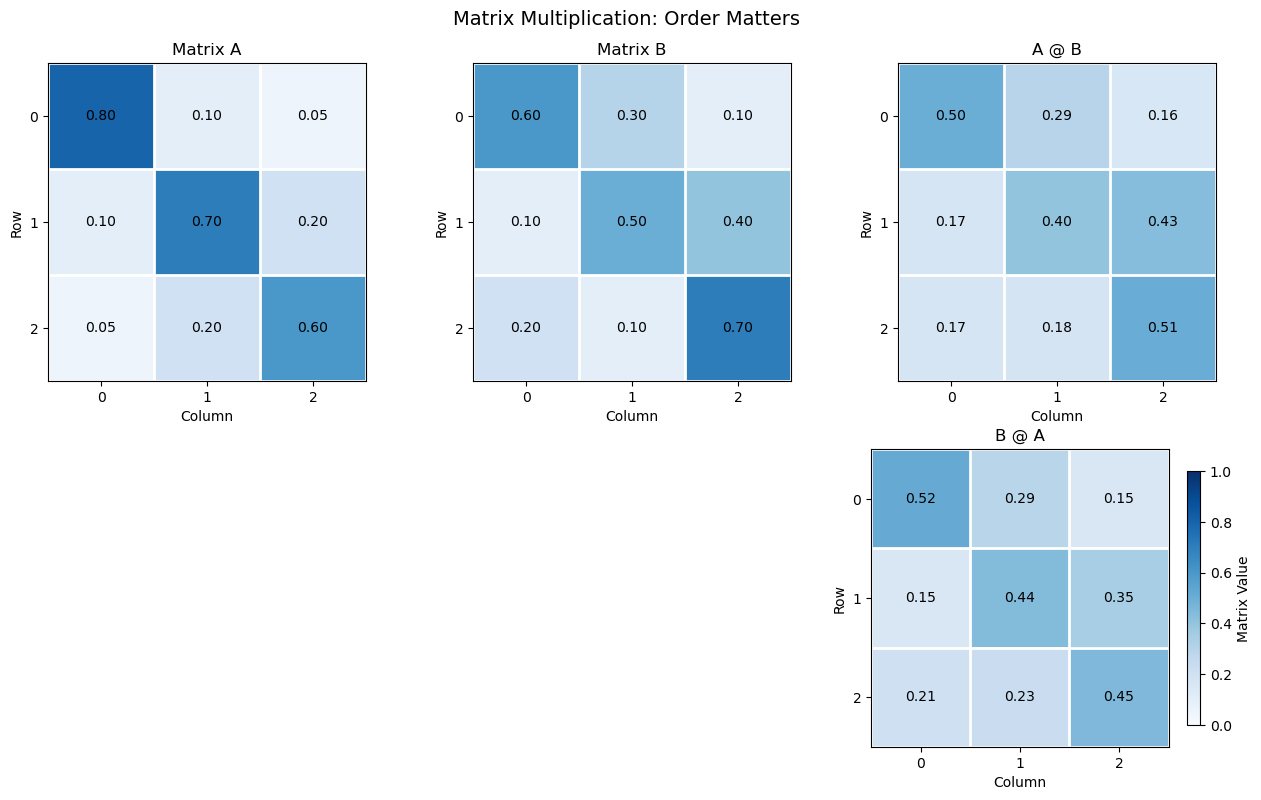

In [268]:
C_AB = A @ B                                                  # matrix multiplication in both orders
C_BA = B @ A

fig, axes = plt.subplots(2, 3, figsize=(13, 8))               # visualize matrices and both multiplication orders

matrices = [A, B, C_AB, None, None, C_BA]
matrix_names = ['Matrix A', 'Matrix B', 'A @ B','', '', 'B @ A']

for ax, matrix, name in zip(axes.flatten(), matrices, matrix_names):
    if matrix is None:
        ax.axis('off')
        continue

    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[1, 2], label='Matrix Value', shrink=0.8); fig.suptitle('Matrix Multiplication: Order Matters', fontsize=14)
plt.tight_layout(); plt.show()

#### Identity Matrix

An identity matrix is a square matrix with ones along the main diagonal and zeros everywhere else. Multiplying a matrix by an identity matrix of compatible dimensions leaves the original matrix unchanged.

The identity matrix is denoted by $\bf I$. For a 3 × 3 identity matrix:

$$
\bf I =
\begin{bmatrix}
1 & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & 1
\end{bmatrix}
$$

For any compatible matrix $\bf A$:

$$
\bf A \bf I = \bf I \bf A = \bf A
$$

Using our example matrix:

$$
\bf A \bf I =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
\begin{bmatrix}
1 & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & 1
\end{bmatrix}
$$

Each element of the resulting matrix is calculated as the dot product of a row of $\bf A$ with a column of $\bf I$:

$$
c_{1,1} = (0.80)(1)+(0.10)(0)+(0.05)(0) = 0.80
$$

$$
c_{1,2} = (0.80)(0)+(0.10)(1)+(0.05)(0) = 0.10
$$

$$
c_{1,3} = (0.80)(0)+(0.10)(0)+(0.05)(1) = 0.05
$$

$$
c_{2,1} = (0.10)(1)+(0.70)(0)+(0.20)(0) = 0.10
$$

$$
c_{2,2} = (0.10)(0)+(0.70)(1)+(0.20)(0) = 0.70
$$

$$
c_{2,3} = (0.10)(0)+(0.70)(0)+(0.20)(1) = 0.20
$$

$$
c_{3,1} = (0.05)(1)+(0.20)(0)+(0.60)(0) = 0.05
$$

$$
c_{3,2} = (0.05)(0)+(0.20)(1)+(0.60)(0) = 0.20
$$

$$
c_{3,3} = (0.05)(0)+(0.20)(0)+(0.60)(1) = 0.60
$$

Combining these nine calculated elements gives the original matrix:

$$
\bf C = \bf A \bf I = \bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

The identity matrix is used in linear algebra and machine learning as the multiplicative identity, as a reference for matrix transformations, and in matrix inversion and solving systems of linear equations.

Note, 

* each column of the identity matrix selects one column of the original matrix through the row-by-column dot products. That is why the original matrix is preserved.

Uses of the identity matrix in machine learning include:

- **Matrix transformations** – represent an unchanged transformation, preserving the original data or feature representation.

- **Weight initialization** – initialize weight matrices to the identity in some neural network architectures to initially preserve input signals.

- **Regularization** – add a scaled identity matrix to covariance or other system matrices to improve numerical stability and ensure invertibility.

- **Ridge regression** – use the identity matrix in the regularized normal equations to penalize model coefficients.

- **Matrix inversion** – define the identity as the result of multiplying a nonsingular matrix by its inverse.

- **Principal Component Analysis (PCA)** – express orthogonality and uncorrelated coordinate transformations through identity covariance matrices for standardized principal components.

- **Linear systems** – use the identity matrix in matrix equations and numerical methods for solving systems of equations.

Let's visualize our matrix, identity matrix and identity matrix multiplication.

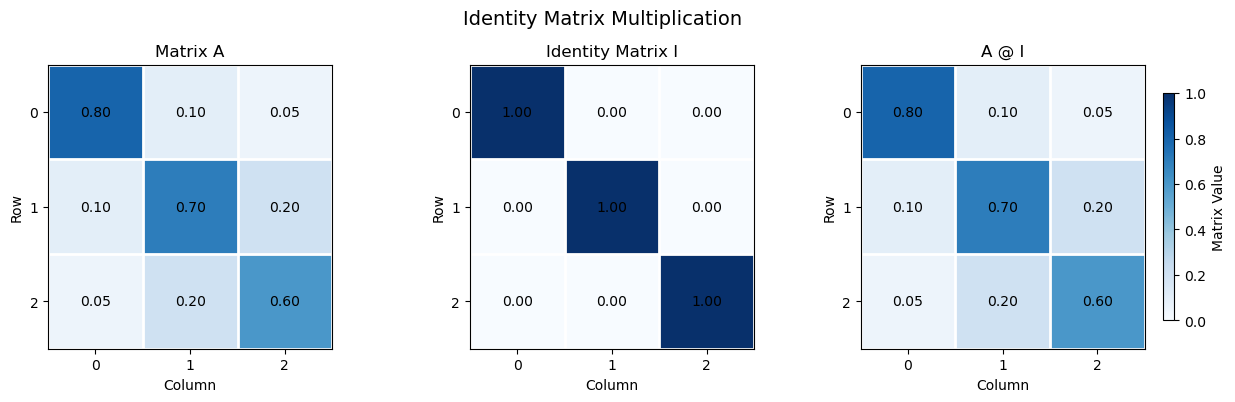

In [269]:
C = A @ I                                                     # matrix multiplication by the identity matrix

fig, axes = plt.subplots(1, 3, figsize=(13, 4))               # visualize matrix A, identity matrix I, and their product

matrices = [A, I, C]
matrix_names = ['Matrix A', 'Identity Matrix I', 'A @ I']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    plot_matrix(ax,matrix,name)

fig.colorbar(im, ax=axes[2], label='Matrix Value', shrink=0.8); fig.suptitle('Identity Matrix Multiplication', fontsize=14)

plt.tight_layout(); plt.show()

#### Inverse Matrix

The inverse of a square matrix is another matrix that, when multiplied by the original matrix, produces the identity matrix. The inverse of a matrix $\bf A$ is denoted by $\bf A^{-1}$.

For a square matrix $\bf A$ to have an inverse, it must be nonsingular, meaning its determinant is nonzero.

$$
\det(\bf A) \neq 0
$$

The inverse matrix satisfies:

$$
\bf A \bf A^{-1} = \bf A^{-1} \bf A = \bf I
$$

Using our example matrix:

$$
\bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

The determinant of this matrix is:

$$
\det(\bf A) = 0.29825
$$

Since the determinant is nonzero, the inverse exists:

$$
\bf A^{-1} \approx
\begin{bmatrix}
1.274 & -0.168 & -0.050 \\
-0.168 & 1.601 & -0.520 \\
-0.050 & -0.520 & 1.844
\end{bmatrix}
$$

Multiplying the original matrix by its inverse gives the identity matrix:

$$
\bf A \bf A^{-1} = \bf I
$$

The inverse matrix is used to solve systems of linear equations. For example, if:

$$
\bf A \bf x = \bf b
$$

then, when $\bf A$ is invertible, the solution is:

$$
\bf x = \bf A^{-1}\bf b
$$

In machine learning, matrix inverses appear in analytical solutions such as ordinary least squares regression. In practice, numerical methods for solving linear systems are generally preferred over explicitly calculating the inverse.

Uses of the inverse matrix in machine learning include:

- **Linear regression** – derive the closed-form least squares solution using the inverse of the feature cross-product matrix, when it is nonsingular.

- **Ridge regression** – calculate regularized regression coefficients using the inverse of the regularized cross-product matrix.

- **Linear systems** – solve systems of equations that arise in parameter estimation and optimization.

- **Gaussian processes** – calculate predictive distributions using inverses of covariance matrices.

- **Multivariate statistics** – calculate the Mahalanobis distance using the inverse covariance matrix to account for relationships between features.

- **Uncertainty estimation** – use inverse information or Hessian matrices to approximate parameter uncertainty in some statistical models.

- **Matrix transformations** – reverse an invertible linear transformation to recover the original representation.

- **Numerical optimization** – use inverse Hessian information in second-order methods, such as Newton's method, to determine parameter updates.

Let's visualize our matrix and the matrix inverse demonstrated above.

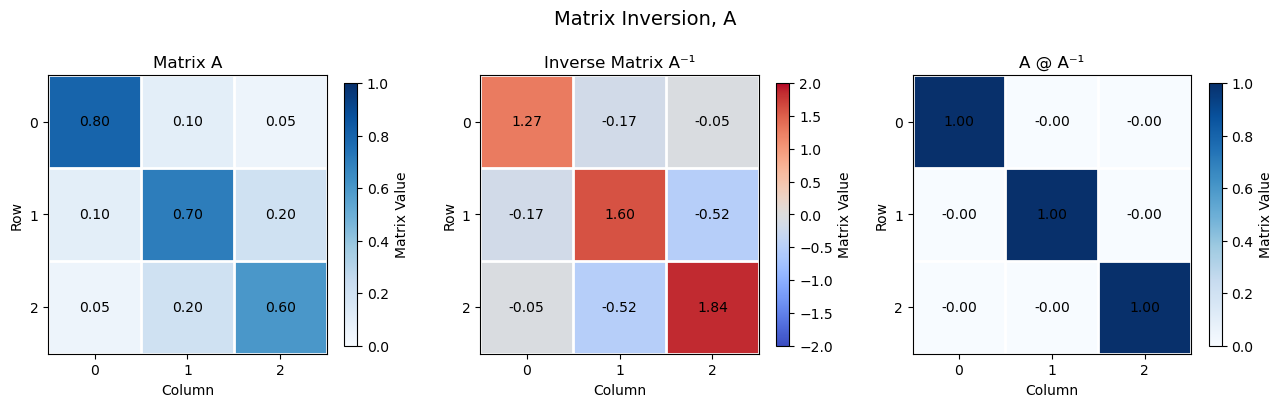

In [270]:
det_A = np.linalg.det(A)                                      # calculate the determinant and inverse of A
A_inv = np.linalg.inv(A)

C = A @ A_inv                                                 # multiply A by its inverse

fig, axes = plt.subplots(1, 3, figsize=(13, 4))               # visualize original matrix, inverse, and product

matrices = [A, A_inv, C]
matrix_names = ['Matrix A', 'Inverse Matrix A⁻¹', 'A @ A⁻¹']

for ax, matrix, name in zip(axes, matrices, matrix_names):
    if name == matrix_names[1]:
        plot_matrix(ax,matrix,name,"coolwarm",-2,2,True)
    else:
        plot_matrix(ax,matrix,name, "Blues",0,1,True)

fig.suptitle('Matrix Inversion, A', fontsize=14)

plt.tight_layout(); plt.show()

#### Angle Between Vectors

The angle between two vectors can be calculated using their dot product and magnitudes. See the [Vector Cosine Similarity](MachineLearning_linear_algebra.html#cosine-similarity) entry for the equation, worked example, and visualization.

#### Orthogonality

Two vectors are orthogonal when they are perpendicular to each other, meaning the angle between them is 90 degrees. Orthogonal vectors have a dot product of zero.

$$
\bf x \cdot \bf z = 0
$$

Using our example vectors:

$$
\bf x =
\begin{bmatrix}
0.20 \\ 0.40 \\ 0.60
\end{bmatrix}
\qquad
\bf z =
\begin{bmatrix}
0.40 \\ -0.20 \\ 0.00
\end{bmatrix}
$$

$$
\bf x \cdot \bf z =
(0.20)(0.40)+(0.40)(-0.20)+(0.60)(0.00)
= 0
$$

Therefore, $\bf x$ and $\bf z$ are orthogonal.

Uses of orthogonality in machine learning include:

- **Principal Component Analysis (PCA)** – principal component directions are orthogonal, allowing data to be represented along independent coordinate directions.

- **Feature engineering** – construct orthogonal features to reduce redundancy and correlation among input variables.

- **Linear regression** – least squares residuals are orthogonal to the column space of the predictor matrix.

- **Neural networks** – orthogonal weight initialization helps preserve signal magnitudes and improve gradient propagation through network layers.

- **Signal processing** – use orthogonal basis vectors to represent signals efficiently without overlap between components.

- **Dimensionality reduction** – represent data using orthogonal directions that capture distinct sources of variation.

- **Regularization and optimization** – orthogonal transformations can help preserve vector norms and improve numerical conditioning.

- **Representation learning** – encourage learned feature or embedding vectors to be orthogonal to reduce redundancy and promote diverse representations.

Orthogonal directions represent independent geometric components, although orthogonality alone does not necessarily imply statistical independence.

Let's visualize our orthogonal vectors as demonstrated above.

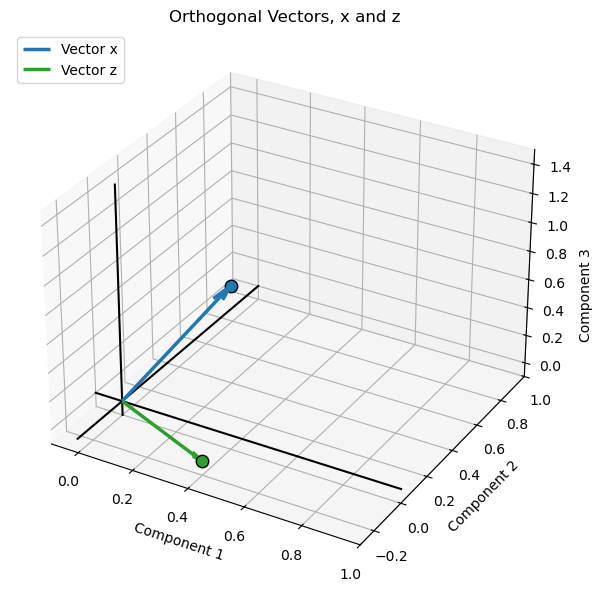

In [271]:
xz_dot = np.dot(x, z)                                         # calculate dot product

fig = plt.figure(figsize=(7, 6))                              # visualize orthogonal vectors
ax = fig.add_subplot(111, projection='3d')

ax.quiver(0, 0, 0, x[0], x[1], x[2],color='tab:blue', linewidth=2.5,arrow_length_ratio=0.12, label='Vector x') # plot vectors from the origin
ax.quiver(0, 0, 0, z[0], z[1], z[2],color='tab:green', linewidth=2.5,arrow_length_ratio=0.12, label='Vector z')

ax.scatter(x[0], x[1], x[2], color='tab:blue',edgecolor='black', s=80) # mark endpoints
ax.scatter(z[0], z[1], z[2], color='tab:green',edgecolor='black', s=80)

format_3d_plot(ax, 0.93, "Orthogonal Vectors, x and z",True)  # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Vector Projection

Vector projection calculates the component of one vector that lies in the direction of another vector. The projection of $\bf x$ onto $\bf y$ is a vector parallel to $\bf y$ that represents the part of $\bf x$ aligned with $\bf y$.

The orthogonal projection of $\bf x$ onto $\bf y$ is calculated as:

$$
\operatorname{proj}_{\bf y}(\bf x) =
\frac{\bf x \cdot \bf y}{\|\bf y\|_2^2}\bf y
$$

where:

- $\bf x \cdot \bf y$ is the dot product of the two vectors.
- $\|\bf y\|_2^2$ is the squared magnitude of the projection direction vector.
- The scalar coefficient determines the length and direction of the projected vector along $\bf y$.

Using our example vectors:

$$
\bf x =\begin{bmatrix}0.20 \\ 0.40 \\ 0.60 \end{bmatrix} \qquad \bf y = \begin{bmatrix} 0.30 \\ 0.50 \\ 0.70 \end{bmatrix}
$$

$$
\operatorname{proj}_{\bf y}(\bf x) = \frac{0.68}{0.83} \begin{bmatrix} 0.30 \\ 0.50 \\ 0.70 \end{bmatrix} \approx
\begin{bmatrix} 0.246 \\ 0.410 \\ 0.573 \end{bmatrix}
$$

The projection is the component of $\bf x$ in the direction of $\bf y$. The difference between the original vector and its projection is perpendicular to $\bf y$.

$$
\bf r = \bf x - \operatorname{proj}_{\bf y}(\bf x)
$$

Vector projections are used in machine learning and applied mathematics for,

* least squares regression

* decomposing vectors into components

* understanding how much of one feature or direction is represented by another

##### Orthogonal Projection

An orthogonal projection projects a vector onto another vector such that the difference between the original vector and its projection is perpendicular to the projection direction. The projected vector is the closest point on the line defined by the projection direction to the original vector's endpoint.

The orthogonal projection of $\bf x$ onto $\bf y$ is:

$$
\operatorname{proj}_{\bf y}(\bf x) =
\frac{\bf x \cdot \bf y}{\|\bf y\|_2^2}\bf y
$$

The remainder vector is:

$$
\bf r = \bf x - \operatorname{proj}_{\bf y}(\bf x)
$$

The defining property of an orthogonal projection is that the remainder is perpendicular to $\bf y$:

$$
\bf r \cdot \bf y = 0
$$

Orthogonal projections are fundamental to least squares regression, where the residual vector is perpendicular to the space spanned by the model predictors.

Uses of vector projection in machine learning include:

- **Principal Component Analysis (PCA)** – project observations onto principal component directions to obtain lower-dimensional representations.

- **Linear regression** – interpret predictions as the projection of the response vector onto the column space of the predictor matrix.

- **Feature decomposition** – separate a vector into components parallel and perpendicular to a specified direction.

- **Similarity analysis** – measure how much one feature or embedding vector aligns with another.

- **Gradient optimization** – project gradients onto constrained directions or feasible subspaces during optimization.

- **Dimensionality reduction** – project high-dimensional data onto a lower-dimensional subspace.

- **Signal processing** – represent signals as projections onto basis vectors or subspaces.

- **Residual analysis** – calculate the component of a vector not explained by its projection, as in least squares.

Let's calculate and visualize orthogonal projection.

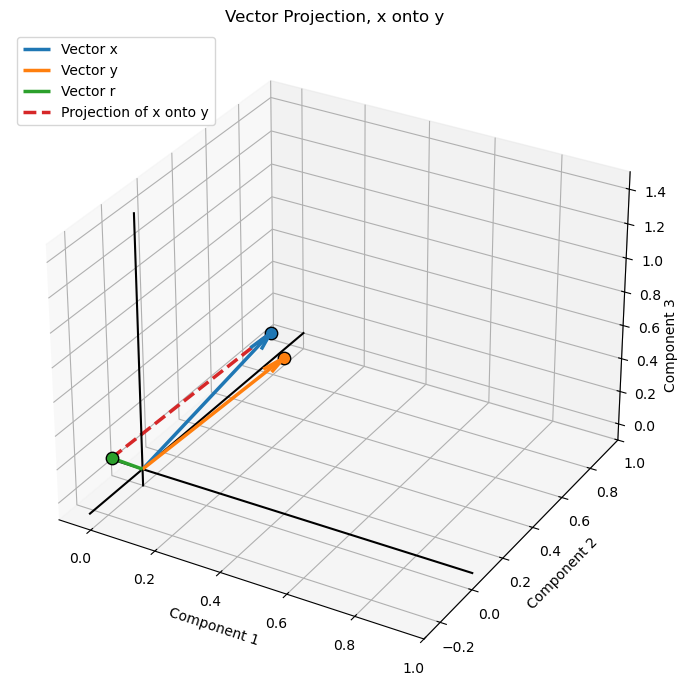

In [272]:
proj_xy = (np.dot(x, y) / np.dot(y, y)) * y                   # calculate projection of x onto y

r = x - proj_xy                                               # calculate perpendicular remainder
  
fig = plt.figure(figsize=(8, 7))                              # create 3D visualization
ax = fig.add_subplot(111, projection='3d')

vectors = [x, y, r]                                           # plot vectors from the origin
names = ['x', 'y', 'r']
colors = ['tab:blue', 'tab:orange', 'tab:green']

for v, name, color in zip(vectors, names, colors):
    ax.quiver(0, 0, 0, v[0], v[1], v[2],color=color, linewidth=2.5,arrow_length_ratio=0.12, label=f'Vector {name}')
    ax.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

ax.plot([r[0], x[0]], [r[1], x[1]], [r[2], x[2]],color='tab:red', linewidth=2.5, linestyle='--',label='Projection of x onto y') # dashed line from r to x

format_3d_plot(ax, 0.92, "Vector Projection, x onto y",True)  # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

##### Non-Orthogonal Projection

A non-orthogonal projection decomposes a vector into a projected component and a remainder that is not necessarily perpendicular to the projection direction. Unlike an orthogonal projection, the projected component is not necessarily the closest point on the projection line to the original vector's endpoint.

For example, a general decomposition of $\bf x$ into two components is:

$$
\bf x = \bf p + \bf r
$$

where $\bf p$ is the projected component and $\bf r$ is the remainder. In a non-orthogonal projection, the remainder is generally not perpendicular to the projection direction:

$$
\bf r \cdot \bf y \neq 0
$$

Non-orthogonal projections are used in oblique coordinate systems and some numerical methods, where components are resolved along directions that are not perpendicular to one another.

Uses of non-orthogonal projection in machine learning include:

- **Oblique dimensionality reduction** – represent data using projection directions that are not mutually perpendicular.

- **Signal decomposition** – separate signals into components using non-orthogonal basis functions.

- **Feature representation** – express observations using correlated or non-orthogonal feature directions.

- **Independent Component Analysis (ICA)** – separate statistically independent source signals using transformations that are generally not constrained to be orthogonal.

- **Oblique factor models** – represent data using latent factors that are allowed to be correlated.

- **Subspace methods** – project data between distinct subspaces that are not necessarily perpendicular.

- **Numerical optimization** – project updates onto constrained or oblique feasible directions when the geometry of the problem requires it.

#### Distance Between Vectors

The distance between two vectors is the magnitude of their difference. It measures the straight-line Euclidean distance between the endpoints of the vectors when they share the same origin.

The Euclidean distance between vectors $\bf x$ and $\bf y$ is:

$$
d(\bf x,\bf y) = \|\bf x-\bf y\|_2
$$

Expanding the equation:

$$
d(\bf x,\bf y) =
\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

Using our example vectors:

$$
d(\bf x,\bf y) =
\sqrt{(0.20-0.30)^2+(0.40-0.50)^2+(0.60-0.70)^2}
$$

$$
= \sqrt{0.03} \approx 0.173
$$

Uses of distance between vectors in machine learning include:

- **Nearest Neighbor Algorithms** – identify observations with the most similar feature vectors using distance measures such as Euclidean distance.

- **Clustering** – group observations based on distances between their feature vectors, as in K-means clustering.

- **Anomaly Detection** – identify observations that are unusually far from typical observations or cluster centers.

- **Classification** – assign labels based on the distances to labeled training observations, as in K-nearest neighbors.

- **Recommendation Systems** – identify similar users or items by comparing their feature or embedding vectors.

- **Embedding Search** – retrieve similar text, images, or other data by measuring distances between learned representations.

- **Model Evaluation** – quantify prediction errors using the distance between observed and predicted vectors.

- **Generative Models** – compare generated and reference data representations using distance-based loss functions.

- **Data Quality** – identify unusual or inconsistent observations by measuring their distance from expected feature representations.

Let's visualize our vectors and distance between two vectors as demonstrated above.

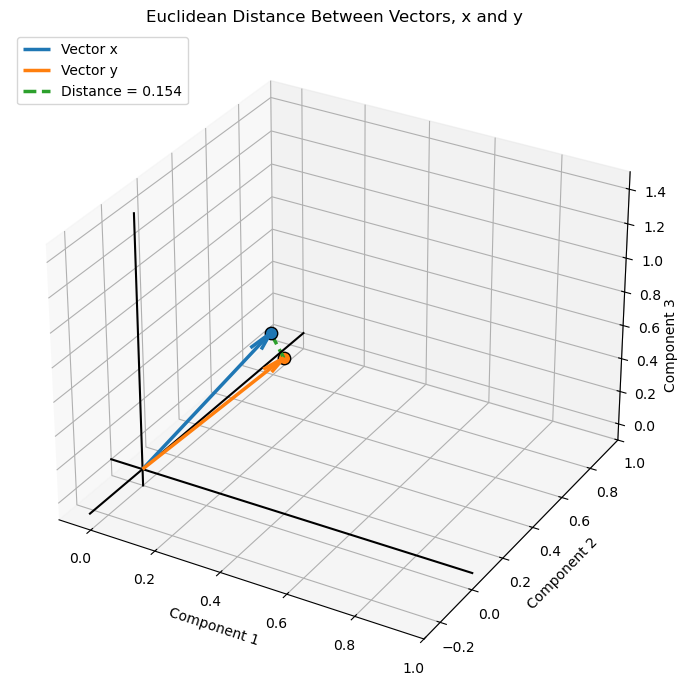

In [273]:
d_xy = x - y                                                  # calculate difference vector and Euclidean distance
distance_xy = np.linalg.norm(d_xy)

fig = plt.figure(figsize=(8, 7))                              # create 3D visualization
ax = fig.add_subplot(111, projection='3d')

vectors = [x, y]                                              # plot vectors from the origin
names = ['x', 'y']
colors = ['tab:blue', 'tab:orange']

for v, name, color in zip(vectors, names, colors):
    ax.quiver(0, 0, 0, v[0], v[1], v[2],color=color, linewidth=2.5,arrow_length_ratio=0.12, label=f'Vector {name}')
    ax.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

ax.plot([x[0], y[0]], [x[1], y[1]], [x[2], y[2]],color='tab:green', linewidth=2.5, linestyle='--',label=f'Distance = {distance_xy:.3f}') # connect vector endpoints 

format_3d_plot(ax, 0.92, "Euclidean Distance Between Vectors, x and y",True) # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Linear Transformation

A linear transformation maps a vector from one space to another using a matrix. It can change the magnitude and direction of a vector, and can also rotate, reflect, stretch, compress, or shear the coordinate space.

A linear transformation is expressed as:

$$
\bf y = \bf A \bf x
$$

where:

- $\bf x$ is the original input vector.
- $\bf A$ is the transformation matrix.
- $\bf y$ is the transformed output vector.

Using our example matrix $\bf A$ and vector $\bf x$:

$$
\bf y = \begin{bmatrix} 0.80 & 0.10 & 0.05 \\ 0.10 & 0.70 & 0.20 \\ 0.05 & 0.20 & 0.60 \end{bmatrix}
\begin{bmatrix} 0.20 \\ 0.40 \\ 0.60 \end{bmatrix}
$$

For the transformation $\bf y = \bf A \bf x$, each element of the resulting vector is calculated as the dot product of a row of $\bf A$ with the input vector $\bf x$:

$$
y_1 = (0.80)(0.20)+(0.10)(0.40)+(0.05)(0.60) = 0.23
$$

$$
y_2 = (0.10)(0.20)+(0.70)(0.40)+(0.20)(0.60) = 0.42
$$

$$
y_3 = (0.05)(0.20)+(0.20)(0.40)+(0.60)(0.60) = 0.45
$$

Combining these three calculated elements gives the transformed vector,

$$
\bf y = \bf A \bf x = \begin{bmatrix} 0.23 \\ 0.42 \\ 0.45 \end{bmatrix}
$$

Each output component is a weighted sum of the input vector components, with the weights provided by the corresponding row of the transformation matrix.

Uses of linear transformations in machine learning include:

- **Neural Networks** – transform input features and hidden-layer representations using learned weight matrices, forming the foundation of fully connected layers.

- **Linear Regression** – map feature vectors to predictions through weighted combinations of input variables.

- **Dimensionality Reduction** – transform high-dimensional observations into lower-dimensional representations using methods such as Principal Component Analysis (PCA).

- **Feature Engineering** – rotate, scale, and combine input features to create new representations that may be more useful for learning.

- **Convolutional Neural Networks** – apply linear transformations to image features through convolutional filters and fully connected layers.

- **Attention Mechanisms** – transform input representations into queries, keys, and values using learned projection matrices.

- **Embedding Models** – map observations, words, images, or other inputs into learned vector spaces.

- **Signal Processing** – transform signals between representations, including Fourier and wavelet transforms.

- **Computer Vision** – transform image coordinates and features through rotation, scaling, and other geometric transformations.

- **Graph Neural Networks** – propagate and combine node features through adjacency and feature transformation matrices.

- **Optimization** – transform gradients and parameter updates to improve the efficiency of learning algorithms.

- **Scientific Computing** – represent physical relationships, coordinate changes, and system behavior through matrix-based transformations.

Let's visualize our vector and a linear transformation, in this case a rotation given an orthogonal matrix.

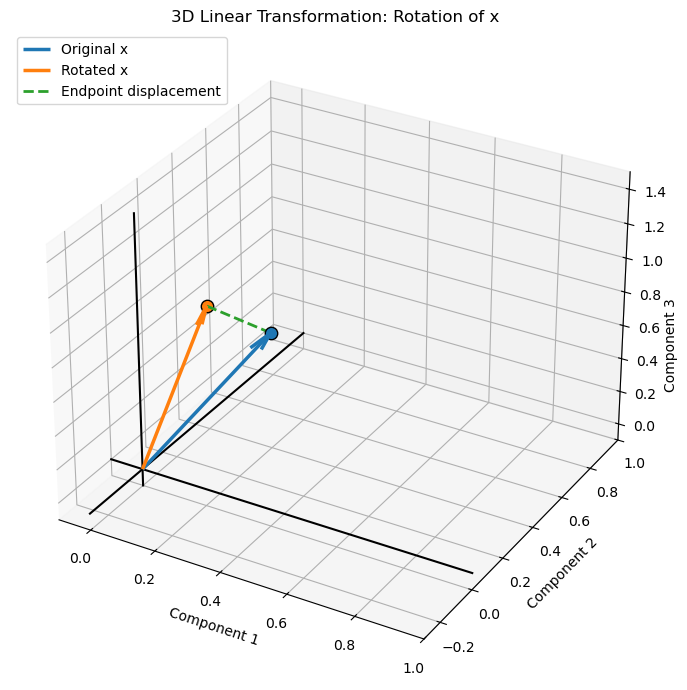

In [274]:
theta = 30                                                    # define rotation angle in degrees
theta_rad = np.radians(theta)

R_z = np.array([                                              # create rotation matrix about the z-axis
    [np.cos(theta_rad), -np.sin(theta_rad), 0],
    [np.sin(theta_rad),  np.cos(theta_rad), 0],
    [0,                  0,                 1]
])

x_rot = R_z @ x                                               # rotate vector x

fig = plt.figure(figsize=(8, 7))                              # create 3D visualization
ax = fig.add_subplot(111, projection='3d')

vectors = [x, x_rot]                                          # plot original and rotated vectors
names = ['Original x', 'Rotated x']
colors = ['tab:blue', 'tab:orange']

for v, name, color in zip(vectors, names, colors):
    ax.quiver(0, 0, 0, v[0], v[1], v[2],color=color, linewidth=2.5,arrow_length_ratio=0.12, label=name)
    ax.scatter(v[0], v[1], v[2], color=color,edgecolor='black', s=80, zorder=3)

ax.plot([x[0], x_rot[0]],[x[1], x_rot[1]],[x[2], x_rot[2]],color='tab:green', linestyle='--', # connect vector endpoints
    linewidth=2, label='Endpoint displacement')

format_3d_plot(ax, 0.92, "3D Linear Transformation: Rotation of x",True) # add axis labels, origin lines and legend

plt.tight_layout(); plt.show()

#### Matrix Rank

The rank of a matrix is the number of linearly independent rows or columns in the matrix. It represents the number of independent dimensions or directions captured by the matrix. The rank cannot exceed the smaller of the number of rows and columns.

For a matrix $\bf A$:

$$
\operatorname{rank}(\bf A) \leq \min(m,n)
$$

A square matrix with full rank has linearly independent rows and columns and is invertible. A matrix with less than full rank is rank-deficient, indicating that some rows or columns can be expressed as linear combinations of others.

For our example matrices:

$$
\operatorname{rank}(\bf A) = 3
$$

$$
\operatorname{rank}(\bf B) = 3
$$

$$
\operatorname{rank}(\bf I) = 3
$$

Matrix rank is important in machine learning for understanding data dimensionality, detecting redundant features, identifying multicollinearity, and determining whether a system of linear equations has a unique solution.

The rank of a matrix can be determined by finding the largest square submatrix with a nonzero determinant. This is called the largest nonzero minor.

For our $3 \times 3$ matrix $\bf A$:

$$
\bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

First, calculate the determinant of the full matrix:

$$
\det(\bf A) =
0.80(0.70 \times 0.60-0.20 \times 0.20)
$$

$$
-0.10(0.10 \times 0.60-0.20 \times 0.05)
$$

$$
+0.05(0.10 \times 0.20-0.70 \times 0.05)
$$

$$
= 0.304-0.005-0.00075 = 0.29825
$$

Since the determinant is nonzero, the matrix has full rank:

$$
\operatorname{rank}(\bf A) = 3
$$

For a square matrix, a nonzero determinant means all rows and columns are linearly independent. If the determinant is zero, the rank is less than 3, and we would examine smaller square submatrices to determine the rank.

Uses of matrix rank in machine learning include:

- **Dimensionality Reduction** – determine the number of independent dimensions represented by a data or feature matrix.

- **Principal Component Analysis (PCA)** – identify the maximum number of nonzero principal components and assess the effective dimensionality of data.

- **Multicollinearity** – detect linearly dependent features that can make regression coefficients non-unique or difficult to estimate.

- **Linear Regression** – determine whether the feature matrix has full column rank, which is required for a unique ordinary least squares coefficient solution.

- **Matrix Factorization** – specify the number of latent dimensions used to approximate large data matrices, as in recommendation systems.

- **Low-Rank Approximation** – compress data and reduce noise by representing a matrix using fewer independent components.

- **Neural Networks** – analyze the expressive capacity and dimensionality of weight transformations.

- **Data Quality** – identify redundant features or measurements that do not contribute additional independent information.

- **Numerical Stability** – detect rank-deficient or nearly rank-deficient matrices that can cause problems in matrix inversion and parameter estimation.

Let's calculate matrix rank for our 3 matrices.

In [275]:
rank_A = np.linalg.matrix_rank(A)                             # calculate matrix ranks
rank_B = np.linalg.matrix_rank(B) 
rank_I = np.linalg.matrix_rank(I)

print('Rank of A:', rank_A); print('Rank of B:', rank_B); print('Rank of I:', rank_I)

Rank of A: 3
Rank of B: 3
Rank of I: 3


#### Matrix Determinant

The determinant is a scalar value calculated from a square matrix. It provides information about the matrix, including whether it is invertible and how it transforms space. A nonzero determinant indicates that the matrix is invertible, while a zero determinant indicates that the matrix is singular.

For a $2 \times 2$ matrix, the determinant is calculated as:

$$
\det(\bf A) =
\begin{vmatrix}
a_{1,1} & a_{1,2} \\
a_{2,1} & a_{2,2}
\end{vmatrix}
= a_{1,1}a_{2,2}-a_{1,2}a_{2,1}
$$

For a $3 \times 3$ matrix, the determinant can be calculated by expanding along the first row:

$$
\det(\bf A) =
a_{1,1}(a_{2,2}a_{3,3}-a_{2,3}a_{3,2})
$$

$$
-a_{1,2}(a_{2,1}a_{3,3}-a_{2,3}a_{3,1})
$$

$$
+a_{1,3}(a_{2,1}a_{3,2}-a_{2,2}a_{3,1})
$$

Using our example matrix:

$$
\det(\bf A) =
0.80(0.70 \times 0.60-0.20 \times 0.20)
$$

$$
-0.10(0.10 \times 0.60-0.20 \times 0.05)
$$

$$
+0.05(0.10 \times 0.20-0.70 \times 0.05)
$$

$$
= 0.304-0.005-0.00075 = 0.29825
$$

Since the determinant is nonzero, $\bf A$ is invertible and has full rank.

Geometrically, 

* the absolute value of the determinant represents the volume scaling factor of a linear transformation

* a negative determinant indicates that the transformation also reverses orientation, while a zero determinant means the transformation collapses at least one dimension

Uses of the matrix determinant in machine learning include:

- **Invertibility** – determine whether a square matrix has an inverse, which is important in solving linear systems and estimating model parameters.

- **Linear Regression** – assess whether the feature cross-product matrix is nonsingular, allowing a unique solution through the normal equations.

- **Multivariate Statistics** – calculate the determinant of covariance matrices as a measure of the generalized variance of a multivariate distribution.

- **Gaussian Processes** – evaluate the log determinant of covariance matrices when calculating the likelihood of observed data.

- **Probability Distributions** – calculate normalization factors in multivariate Gaussian probability density functions using the covariance determinant.

- **Geometric Transformations** – quantify how a linear transformation scales area or volume through the absolute value of its determinant.

- **Numerical Stability** – identify singular or nearly singular matrices that may cause difficulties in matrix inversion and parameter estimation.

- **Information Theory** – use the log determinant of covariance matrices to quantify aspects of multivariate uncertainty and information.

- **Matrix Decomposition** – use determinant properties to relate the eigenvalues of a square matrix to their product.

Let's calculate matrix determinants for our 3 matrices.

In [276]:
det_A = np.linalg.det(A)                                      # calculate determinants
det_B = np.linalg.det(B)
det_I = np.linalg.det(I)

print('Determinant of A:', det_A); print('Determinant of B:', det_B); print('Determinant of I:', det_I)

Determinant of A: 0.29825
Determinant of B: 0.18000000000000002
Determinant of I: 1.0


#### Matrix Trace

The trace of a square matrix is the sum of its diagonal elements, from the upper-left to the lower-right corner. The trace is a scalar value that summarizes the diagonal of a matrix.

For a square matrix $\bf A$ with dimensions $n \times n$, the trace is:

$$
\operatorname{tr}(\bf A) = \sum_{i=1}^{n}a_{i,i}
$$

For our example matrix:

$$
\operatorname{tr}(\bf A) = 0.80 + 0.70 + 0.60 = 2.10
$$

The trace of the matrix is therefore:

$$
\operatorname{tr}(\bf A) = 2.10
$$

For our 3D rotation matrix about the z-axis:

$$
\operatorname{tr}(\bf R_z) =
\cos(\theta)+\cos(\theta)+1
= 2\cos(\theta)+1
$$

For a rotation of 30 degrees:

$$
\operatorname{tr}(\bf R_z) =
2(0.866)+1 = 2.732
$$

Matrix trace is used in linear algebra, statistics, and machine learning, including covariance analysis, matrix decompositions, and optimization involving matrices. It also has useful properties, such as the trace of a sum being the sum of the traces:

$$
\operatorname{tr}(\bf A+\bf B) =
\operatorname{tr}(\bf A)+\operatorname{tr}(\bf B)
$$

Uses of the matrix trace in machine learning include:

- **Covariance Analysis** – calculate the total variance across features by summing the diagonal elements of a covariance matrix.

- **Principal Component Analysis (PCA)** – calculate total data variance, which equals the sum of the eigenvalues of the covariance matrix.

- **Regularization** – use trace-based penalties to constrain model parameters or covariance matrices.

- **Multivariate Statistics** – express statistical quantities such as the expected squared distance and total variance using matrix traces.

- **Optimization** – simplify matrix derivatives and objective functions in machine learning algorithms using trace identities.

- **Matrix Decomposition** – calculate the sum of eigenvalues of a square matrix, including covariance and transformation matrices.

- **Model Evaluation** – quantify reconstruction error and approximation quality using the trace of error-related matrices.

- **Linear Algebra** – exploit trace properties, such as invariance under cyclic permutation, to simplify matrix expressions in derivations.

#### Eigenvalues and Eigenvectors

An eigenvector of a square matrix is a nonzero vector whose direction remains unchanged after a linear transformation by that matrix. 

* the eigenvalue is the scalar that describes how the eigenvector is stretched, compressed, or reversed.

The eigenvalue equation is:

$$
\bf A \bf v = \lambda \bf v
$$

where:

- $\bf A$ is a square transformation matrix.
- $\bf v$ is a nonzero eigenvector.
- $\lambda$ is the corresponding eigenvalue.

Eigenvalues can be calculated by solving the characteristic equation:

$$
\det(\bf A-\lambda\bf I)=0
$$

Once an eigenvalue is determined, its corresponding eigenvector is found by solving:

$$
(\bf A-\lambda\bf I)\bf v = \bf 0
$$

Using our example matrix:

$$
\bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

We start with the characteristic equation:

$$
\det(\bf A-\lambda\bf I)=0
$$

Substituting our matrix:

$$
\det
\begin{bmatrix}
0.80-\lambda & 0.10 & 0.05 \\
0.10 & 0.70-\lambda & 0.20 \\
0.05 & 0.20 & 0.60-\lambda
\end{bmatrix}
=0
$$

Expand the determinant along the first row:

$$
(0.80-\lambda)
\begin{vmatrix}
0.70-\lambda & 0.20 \\
0.20 & 0.60-\lambda
\end{vmatrix}
-
0.10
\begin{vmatrix}
0.10 & 0.20 \\
0.05 & 0.60-\lambda
\end{vmatrix}
+
0.05
\begin{vmatrix}
0.10 & 0.70-\lambda \\
0.05 & 0.20
\end{vmatrix}
=0
$$

Evaluating the $2 \times 2$ determinants:

$$
(0.80-\lambda)[(0.70-\lambda)(0.60-\lambda)-(0.20)(0.20)]
$$

$$
-0.10[(0.10)(0.60-\lambda)-(0.20)(0.05)]
$$

$$
+0.05[(0.10)(0.20)-(0.70-\lambda)(0.05)]
=0
$$

Expanding and collecting terms gives the characteristic polynomial:

$$
-\lambda^3+2.10\lambda^2-1.4075\lambda+0.29825=0
$$

Multiplying by $-1$:

$$
\lambda^3-2.10\lambda^2+1.4075\lambda-0.29825=0
$$

Solving this cubic equation numerically gives three eigenvalues:

$$
\boxed{
\begin{aligned}
\lambda_1 &= 0.442354 \\
\lambda_2 &= 0.716066 \\
\lambda_3 &= 0.941579
\end{aligned}
}
$$

Once we have the eigenvalues, we calculate each corresponding eigenvector by solving:

$$
(\bf A-\lambda\bf I)\bf v=\bf 0
$$

For each eigenvalue, we substitute its value into the matrix, solve the resulting system of equations, and normalize the eigenvector to have a magnitude of one.

Let the eigenvector be:

$$
\bf v =
\begin{bmatrix}
v_1 \\ v_2 \\ v_3
\end{bmatrix}
$$

For each eigenvalue, the first two equations are:

$$
(0.80-\lambda)v_1+0.10v_2+0.05v_3=0
$$

$$
0.10v_1+(0.70-\lambda)v_2+0.20v_3=0
$$

We can set $v_3=1$ to solve for the relative values of $v_1$ and $v_2$. We then normalize the resulting vector.

**Eigenvector 1**: using $\lambda_1=0.442354$,

$$
\begin{aligned}
0.357646v_1+0.10v_2+0.05 &= 0 \\
0.10v_1+0.257646v_2+0.20 &= 0
\end{aligned}
$$

Solving gives:

$$
\bf v_1 \propto
\begin{bmatrix}
0.086647 \\ -0.809890 \\ 1
\end{bmatrix}
$$

Normalizing:

$$
\bf v_1 \approx
\begin{bmatrix}
0.067182 \\ -0.627948 \\ 0.775350
\end{bmatrix}
$$

**Eigenvector 2**: using $\lambda_2=0.716066$,

$$
\begin{aligned}
0.083934v_1+0.10v_2+0.05 &= 0 \\
0.10v_1-0.016066v_2+0.20 &= 0
\end{aligned}
$$

Solving gives:

$$
\bf v_2 \propto
\begin{bmatrix}
-1.833133 \\ 1.038615 \\ 1
\end{bmatrix}
$$

Normalizing:

$$
\bf v_2 \approx
\begin{bmatrix}
-0.786014 \\ 0.445339 \\ 0.428782
\end{bmatrix}
$$

**Eigenvector 3**: using $\lambda_3=0.941579$,

$$
\begin{aligned}
-0.141579v_1+0.10v_2+0.05 &= 0 \\
0.10v_1-0.241579v_2+0.20 &= 0
\end{aligned}
$$

Solving gives:

$$
\bf v_3 \propto
\begin{bmatrix}
1.325433 \\ 1.376538 \\ 1
\end{bmatrix}
$$

Normalizing:

$$
\bf v_3 \approx
\begin{bmatrix}
0.614547 \\ 0.638243 \\ 0.463658
\end{bmatrix}
$$

The eigenvalues and their corresponding normalized eigenvectors are:

$$
\lambda_1=0.442354,\qquad
\bf v_1 =
\begin{bmatrix}
0.067182 \\ -0.627948 \\ 0.775350
\end{bmatrix}
$$

$$
\lambda_2=0.716066,\qquad
\bf v_2 =
\begin{bmatrix}
-0.786014 \\ 0.445339 \\ 0.428782
\end{bmatrix}
$$

$$
\lambda_3=0.941579,\qquad
\bf v_3 =
\begin{bmatrix}
0.614547 \\ 0.638243 \\ 0.463658
\end{bmatrix}
$$

The eigenvectors form the columns of the eigenvector matrix $\bf V$:

$$
\bf V =
\begin{bmatrix}
0.067182 & -0.786014 & 0.614547 \\
-0.627948 & 0.445339 & 0.638243 \\
0.775350 & 0.428782 & 0.463658
\end{bmatrix}
$$

The corresponding diagonal eigenvalue matrix is:

$$
\bf \Lambda =
\begin{bmatrix}
0.442354 & 0 & 0 \\
0 & 0.716066 & 0 \\
0 & 0 & 0.941579
\end{bmatrix}
$$

Observations, 

* setting $v_3=1$ is simply a convenient way to calculate the relative components. Eigenvectors can be multiplied by any nonzero scalar and remain valid eigenvectors.

* the eigenvectors are normalized here, and because $\bf{A}$ is symmetric, they are mutually orthogonal.

* the eigenvalues are all positive and less than one, so this transformation contracts vectors along all three eigenvector directions.

For our symmetric matrix, the eigenvalue decomposition is:

$$
\bf A = \bf V \bf \Lambda \bf V^T
$$

This decomposition represents the original matrix as a combination of its principal directions (eigenvectors) and the scaling factors along those directions (eigenvalues).

Note, 

* the eigenvalues and eigenvectors describe the principal directions of this transformation. Each eigenvector is transformed into a scalar multiple of itself, with the corresponding eigenvalue determining the scaling factor.

Uses of eigenvalues and eigenvectors in machine learning include:

- **Principal Component Analysis (PCA)** – calculate principal component directions from the eigenvectors of the covariance matrix, with eigenvalues indicating the variance captured along each direction.

- **Dimensionality Reduction** – identify dominant directions of variation and retain the eigenvectors associated with the largest eigenvalues.

- **Spectral Clustering** – use eigenvectors of graph Laplacian matrices to identify clusters and reveal structure in complex datasets.

- **Graph Neural Networks** – analyze graph structure and information propagation through eigenvalues and eigenvectors of adjacency or graph Laplacian matrices.

- **Stability Analysis** – assess whether iterative algorithms and dynamical systems converge or diverge based on their eigenvalues.

- **Multivariate Statistics** – characterize covariance matrices, including their principal directions and associated variances.

- **Matrix Decomposition** – represent symmetric matrices through eigenvalue decomposition, supporting matrix transformations and efficient computation.

- **Numerical Optimization** – examine eigenvalues of Hessian matrices to understand curvature and identify minima, maxima, or saddle points.

- **Markov Models** – analyze long-term behavior and stationary distributions of transition matrices through their eigenvalues and eigenvectors.

- **Image Processing** – use eigenvalue-based methods for image compression, dimensionality reduction, and feature extraction.

Let's calculate the eigenvalues and eigenvectors for our matrix as calculated above.

In [277]:
eigenvalues, eigenvectors = np.linalg.eigh(A)                 # calculate eigenvalues and eigenvectors

print('Eigenvalues:'); print(eigenvalues)

print('\nEigenvectors (columns):'); print(eigenvectors)

for i in range(len(eigenvalues)):                             # verify the eigenvalue equation for each eigenpair
    lhs = A @ eigenvectors[:, i]
    rhs = eigenvalues[i] * eigenvectors[:, i]
    print(f'\nEigenpair {i+1}:'); print('A @ v:', lhs); print('lambda * v:', rhs)

Eigenvalues:
[0.44235431 0.71606635 0.94157933]

Eigenvectors (columns):
[[ 0.06718196 -0.7860144  -0.61454694]
 [-0.62794833  0.44533948 -0.63824262]
 [ 0.77534991  0.42878211 -0.46365765]]

Eigenpair 1:
A @ v: [ 0.02971823 -0.27777565  0.34297938]
lambda * v: [ 0.02971823 -0.27777565  0.34297938]

Eigenpair 2:
A @ v: [-0.56283847  0.31889262  0.30703644]
lambda * v: [-0.56283847  0.31889262  0.30703644]

Eigenpair 3:
A @ v: [-0.5786447  -0.60095606 -0.43657046]
lambda * v: [-0.5786447  -0.60095606 -0.43657046]


#### Singular Value Decomposition

Singular Value Decomposition (SVD) is a matrix factorization that decomposes a matrix into three matrices: $\bf U$, $\bf \Sigma$, and $\bf V^T$. The decomposition separates a matrix transformation into rotations or reflections, scaling, and another rotation or reflection. SVD can be applied to any real matrix, including rectangular matrices.

The SVD of a matrix $\bf A$ is:

$$
\bf A = \bf U \bf \Sigma \bf V^T
$$

where:
- $\bf U$ is the left singular vector matrix, containing orthonormal columns.
- $\bf \Sigma$ is a diagonal matrix containing the singular values, which are nonnegative and conventionally ordered from largest to smallest.
- $\bf V^T$ is the transpose of the right singular vector matrix, whose columns in $\bf V$ are orthonormal.

For our example matrix:

$$
\bf A =
\begin{bmatrix}
0.80 & 0.10 & 0.05 \\
0.10 & 0.70 & 0.20 \\
0.05 & 0.20 & 0.60
\end{bmatrix}
$$

We can calculate its SVD numerically using NumPy:

Note, 
* **eigenvalue decomposition** describes the special directions that remain unchanged in direction under a square matrix transformation, while **SVD** provides orthogonal input and output directions and works for rectangular matrices as well.

In [278]:
U, singular_values, V_T = np.linalg.svd(A)                    # perform sigular value decomposition

Sigma = np.diag(singular_values)                              # convert the singular values into a diagonal matrix

print('U:\n', U); print('Singular values:\n', singular_values)
print('Sigma:\n', Sigma); print('V transpose:\n', V_T)

A_reconstructed = U @ Sigma @ V_T                             # reconstruct the original matrix

print('A reconstructed:\n', A_reconstructed)

U:
 [[-0.61454694  0.7860144   0.06718196]
 [-0.63824262 -0.44533948 -0.62794833]
 [-0.46365765 -0.42878211  0.77534991]]
Singular values:
 [0.94157933 0.71606635 0.44235431]
Sigma:
 [[0.94157933 0.         0.        ]
 [0.         0.71606635 0.        ]
 [0.         0.         0.44235431]]
V transpose:
 [[-0.61454694 -0.63824262 -0.46365765]
 [ 0.7860144  -0.44533948 -0.42878211]
 [ 0.06718196 -0.62794833  0.77534991]]
A reconstructed:
 [[0.8  0.1  0.05]
 [0.1  0.7  0.2 ]
 [0.05 0.2  0.6 ]]


#### Matrix Least Squares Solution

The least squares solution is a method for finding the best-fitting solution to a system of linear equations, particularly when there are more equations than unknowns or when an exact solution does not exist. It finds the solution that minimizes the sum of squared differences between the observed values and the values predicted by the linear model.

Consider a system of linear equations:

$$
\bf A\bf x = \bf b
$$

where:
- $\bf A$ is the matrix of known coefficients.
- $\bf x$ is the vector of unknown values.
- $\bf b$ is the vector of observed values.

When an exact solution does not exist, the least squares solution minimizes the squared residuals:

$$
\hat{\bf x} =
\underset{\bf x}{\operatorname{argmin}}
\|\bf A\bf x-\bf b\|_2^2
$$

For a matrix $\bf A$ with full column rank, the solution can be calculated using the normal equations:

$$
\bf A^T\bf A\hat{\bf x} = \bf A^T\bf b
$$

Therefore:

$$
\hat{\bf x} =
(\bf A^T\bf A)^{-1}\bf A^T\bf b
$$

For a general system, the least squares solution can be calculated numerically using the pseudoinverse:

$$
\hat{\bf x} = \bf A^+\bf b
$$

where $\bf A^+$ is the Moore-Penrose pseudoinverse.

Uses of the matrix least squares solution in machine learning include:

- **Linear Regression** – estimate model coefficients by minimizing the sum of squared differences between observed and predicted values.

- **Polynomial Regression** – fit polynomial models by expressing polynomial terms as columns in a feature matrix and solving a least squares problem.

- **Parameter Estimation** – estimate unknown model parameters from observations when the system is overdetermined or noisy.

- **Curve Fitting** – find the best-fitting mathematical relationship between input variables and observed responses.

- **Signal Processing** – estimate signal components and reconstruct signals from noisy or incomplete measurements.

- **Inverse Problems** – estimate unknown subsurface or physical properties from indirect observations, such as geophysical measurements.

- **Regularized Regression** – extend least squares with penalties, as in Ridge regression, to improve stability and control coefficient magnitudes.

- **Neural Networks** – solve linear output-layer or final-layer parameter estimation problems, including least squares fitting of model predictions.

- **Numerical Optimization** – provide a foundation for methods such as Gauss–Newton and nonlinear least squares.

- **Model Calibration** – estimate parameters that minimize the discrepancy between model predictions and observed data.

In [279]:
A_ls = np.array([[1.0, 1.0],                                  # define an example system with more equations than unknowns
                 [1.0, 2.0],
                 [1.0, 3.0],
                 [1.0, 4.0]])

b_ls = np.array([2.0, 2.5, 3.5, 4.0])

x_ls = np.linalg.lstsq(A_ls, b_ls, rcond=None)[0]             # calculate the least squares solution

b_pred = A_ls @ x_ls                                          # calculate predictions and residuals
residuals = b_ls - b_pred

print('Least squares solution:', x_ls); print('Predicted values:', b_pred)
print('Residuals:', residuals); print('Sum of squared residuals:', np.sum(residuals**2))

Least squares solution: [1.25 0.7 ]
Predicted values: [1.95 2.65 3.35 4.05]
Residuals: [ 0.05 -0.15  0.15 -0.05]
Sum of squared residuals: 0.050000000000000044


#### Comments

This was a short sumary of linear algebra prerequisites for machine learning. Much more can be done, I have other demonstrations for modeling workflows with GeostatsPy in the GitHub repository [GeostatsPy_Demos](https://github.com/GeostatsGuy/GeostatsPy_Demos/tree/main).

I hope this is helpful,

*Michael*
  
I hope this was helpful,

*Michael*

#### About the Author

<figure style="text-align: center;">
  <img src="_static/intro/michael_pyrcz_officeshot_jacket.jpg" style="display: block; margin: 0 auto; width: 70%;">
  <figcaption style="text-align: center;"> Professor Michael Pyrcz in his office on the 40 acres, campus of The University of Texas at Austin.
</figcaption>
</figure>

Michael Pyrcz is a professor in the [Cockrell School of Engineering](https://cockrell.utexas.edu/faculty-directory/alphabetical/p), and the [Jackson School of Geosciences](https://www.jsg.utexas.edu/researcher/michael_pyrcz/), at [The University of Texas at Austin](https://www.utexas.edu/), where he researches and teaches subsurface, spatial [data analytics](MachineLearning_glossary_d_f.ipynb#data-analytics), [geostatistics](MachineLearning_glossary_g_l.ipynb#geostatistics), and machine learning. Michael is also,

* the principal investigator of the [Energy Analytics](https://fri.cns.utexas.edu/energy-analytics) freshmen research initiative and a [core](MachineLearning_glossary_a_c.ipynb#core) faculty in the Machine Learn Laboratory in the College of Natural Sciences, The University of Texas at Austin

* an associate editor for [Computers and Geosciences](https://www.sciencedirect.com/journal/computers-and-geosciences/about/editorial-board), and a board member for [Mathematical Geosciences](https://link.springer.com/journal/11004/editorial-board), the International Association for Mathematical Geosciences. 

Michael has written over 100 [peer-reviewed publications](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en), a [Python package](https://pypi.org/project/geostatspy/) for spatial [data](MachineLearning_glossary_d_f.ipynb#data) analytics, co-authored a textbook on spatial data analytics, [Geostatistical Reservoir Modeling](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) and author of two recently released e-books, [Applied Geostatistics in Python: a Hands-on Guide with GeostatsPy](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) and [Applied Machine Learning in Python: a Hands-on Guide with Code](https://geostatsguy.github.io/MachineLearningDemos_Book/intro.html).

All of Michael’s university lectures are available on his [YouTube Channel](https://www.youtube.com/@GeostatsGuyLectures) with links to 100s of Python interactive dashboards and well-documented workflows in over 40 repositories on his [GitHub account](https://github.com/GeostatsGuy), to support any interested students and working professionals with evergreen content. To find out more about Michael’s work and shared educational resources visit his [Website](https://https://www.michaelpyrcz.com).

#### Want to Work Together?

I hope this content is helpful to those that want to learn more about subsurface modeling, [data analytics](MachineLearning_glossary_d_f.ipynb#data-analytics) and machine learning. Students and working professionals are welcome to participate.

* Want to invite me to visit your company for training, mentoring, project review, workflow design and / or consulting? I'd be happy to drop by and work with you! 

* Interested in partnering, supporting my graduate student research or my Subsurface [Data](MachineLearning_glossary_d_f.ipynb#data) Analytics and Machine Learning consortium (co-PI is Professor John Foster)? My research combines data analytics, stochastic modeling and machine learning theory with practice to develop novel methods and workflows to add [value](MachineLearning_glossary_s_z.ipynb#value). We are solving challenging subsurface problems!

* I can be reached at mpyrcz@austin.utexas.edu.

I'm always happy to discuss,

*Michael*

Michael Pyrcz, Ph.D., P.Eng. Professor, Cockrell School of Engineering and The Jackson School of Geosciences, The University of Texas at Austin

More Resources Available at: [Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)